# Microbioma bacteriano de solos expostos a plásticos — `conjunto_alex`

Análise integrada de **483 amostras de solo/rizosfera/plastisfera (16S rRNA)** de **9 BioProjects**, com **metadados corrigidos** (dados em `results/conjunto_alex`)
e dos metadados complementares de `results/dados_complementares/Database_Plastic-Soil.xlsx`.

**Perguntas**
1. Qual a composição taxonômica geral e como ela varia entre estudos, polímeros e frações do solo?
2. Plásticos alteram a diversidade alfa (riqueza/uniformidade) em relação aos controles?
3. Plásticos alteram a estrutura da comunidade (diversidade beta)? Quanto isso pesa frente ao efeito do estudo?
4. Plásticos biodegradáveis e não biodegradáveis têm efeitos diferentes?
5. Quais gêneros respondem de forma consistente aos plásticos (entre estudos) e quais são enriquecidos na plastisfera?
6. Efeitos específicos: dose/tempo/envelhecimento (PRJNA1021161), glifosato (PRJNA1155845), N (PRJNA702448), rizosfera (PRJNA1054347).

**Estratégia contra efeito de lote.** Os estudos usam regiões diferentes do 16S (V4 × V3‑V4), primers,
plataformas e solos distintos. Por isso: (i) comparações **entre estudos** são feitas no nível de **gênero**;
(ii) testes de efeito do plástico são feitos **dentro de cada estudo** (ASV) e depois **combinados**
(meta-análise de efeitos aleatórios / modelos mistos / PERMANOVA com permutações restritas ao estudo).

Figuras → `figuras/`, tabelas → `tabelas/`. Conclusões resumidas em `CONCLUSOES.md`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
import skbio
from skbio.diversity import alpha_diversity, beta_diversity
from skbio.stats.ordination import pcoa

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110; plt.rcParams['savefig.bbox'] = 'tight'

DATA = Path('../results/conjunto_alex'); COMP = Path('../results/dados_complementares/Database_Plastic-Soil.xlsx')
FIG, TAB = Path('figuras'), Path('tabelas'); FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
RNG = np.random.default_rng(42)
def savefig(name): plt.savefig(FIG / f'{name}.png', dpi=150); plt.show()

## 1. Dados e harmonização dos metadados

In [2]:
asv = pd.read_csv(DATA / 'asv_table.tsv', sep='\t', index_col=0)
tax = pd.read_csv(DATA / 'taxonomy.tsv', sep='\t', index_col=0)
meta = pd.read_csv(DATA / 'meta.tsv', sep='\t', index_col=0).loc[asv.columns]
tree = skbio.TreeNode.read(str(DATA / 'tree.nwk'))

main = pd.read_excel(COMP, 'MAIN - BACTERIA', header=1)
main.columns = ['ID','BIOPROJECT','SOURCE','POLYMERS','COLOR','FORMAT','SIZE','SOIL_PARAMS','NOTES',
                'PLATFORM','PRIMERS','REGION','DNA_cDNA','N_DNA','N_cDNA','P1','P2','P3','STATUS','OWNER']
main = main.dropna(subset=['BIOPROJECT'])
proj_info = main.set_index('BIOPROJECT')[['SOURCE','POLYMERS','FORMAT','SIZE','PLATFORM','PRIMERS','REGION','N_DNA','NOTES','STATUS']]
print('ASVs:', asv.shape[0], '| amostras:', asv.shape[1])
proj_info.assign(no_conjunto=proj_info.index.isin(meta.BIOPROJECT))

ASVs: 47472 | amostras: 553


,SOURCE,POLYMERS,FORMAT,SIZE,PLATFORM,PRIMERS,REGION,N_DNA,NOTES,STATUS,no_conjunto
BIOPROJECT,,,,,,,,,,,
PRJNA1079663,Landfill soil,1. PP; 2. PVC; 3. PLA; 4. PC,Particle,20-800uM,Illumina_NovaSeq,27F_1492R,V1-V9,5,NaN,DONE,False
PRJNA1054347,soil,1. PE; 2. PBAT,Film,100cm - wide; 0.01mm thick,Illumina Novaseq,338F_806R,V3–V4,36,They used plastic to mulch the soil in maize c...,DONE,True
PRJNA1021161,soil,1. PE; 2. PLA,Particle,75uM,Illumina Novaseq,341F_806R,V3–V4,111,Application of 0.5% (w/w) and 1.5% (w/w) of MP...,DONE,True
PRJNA932786,soil / worms,1. PBAT; 2. LDPE,Particle,250uM,Illumina MiSeq,515F_806R,V4,36,Mesocosms,DONE,True
PRJNA882093,soil,NaN,NaN,NaN,IlluminaHiSeq,-,V3-V4,2,NO PLASTIC,PROBLEM,False
PRJNA853344,soil,1. PBSA,Film,<1 mm,Illumina MiSeq,515F_806R,V3-V4,12,NaN,DONE,False
PRJNA702448,soil,1. PBSA,Film,2–5 mm × 2–5 mm,Illumina MiSeq,515F_806R,V3-V4,31,NaN,DONE,True
PRJNA673325,soil,NaN,NaN,NaN,Illumina HiSeq2500 PE250,515F_806R,V3-V4,30,NaN,PROBLEM,False
PRJNA630025,soil,1. PLA; 2. PBAT; 3. PE,Film,4 × 4 cm,Illumina MiSeq,27F_907R,V3–V4,36,Há tabela com todos os parametros do solo,DONE,True


**Metadados corrigidos.** Os metadados vêm de `meta_corrigida.tsv`, gerado por `gerar_correcoes.py` + `preparar_metadados.py`
a partir da comparação com o NCBI/ENA e os artigos originais (ver `CORRECOES_METADADOS.md`).

Este notebook trata do **solo** (bulk, rizosfera e plastisfera de campo). Ficam de fora e são analisados em
`analise_v2_comparacoes.ipynb`: 24 amostras de **intestino de *Enchytraeus crypticus*** (PRJNA1155845) e 46 **culturas de
enriquecimento** de laboratório (PRJNA631499, 2016‑07). `CLASSE` = Controle / Papel (mulch de celulose "Weedguard") /
Biodegradável / Não biodegradável.

In [3]:
meta_all = pd.read_csv('meta_corrigida.tsv', sep='\t', index_col=0).loc[asv.columns]
excl = meta_all.COMPARTIMENTO.isin(['Intestino', 'Enriquecimento'])
print('Excluídas deste notebook:', meta_all[excl].groupby(['BIOPROJECT', 'COMPARTIMENTO']).size().to_dict())
meta = meta_all[~excl].copy()
asv = asv[meta.index]; asv = asv.loc[asv.sum(1) > 0]
print('Amostras analisadas:', meta.shape[0], '| ASVs:', asv.shape[0])

resumo = (meta.groupby('BIOPROJECT')
          .agg(n=('POLYMER','size'), regiao=('REGIAO','first'), pais=('COUNTRY','first'),
               experimento=('EXPERIMENT_TYPE','first'), fracoes=('SOIL_FRACTION', lambda s: ', '.join(sorted(s.unique()))),
               polimeros=('POLYMER', lambda s: ', '.join(f'{k}:{v}' for k, v in s.value_counts().items())))
          .join(proj_info[['PLATFORM','PRIMERS','FORMAT','SIZE']]))
resumo.to_csv(TAB / '01_resumo_projetos.csv'); resumo

Excluídas deste notebook: {('PRJNA1155845', 'Intestino'): 24, ('PRJNA631499', 'Enriquecimento'): 46}


Amostras analisadas: 483 | ASVs: 47190


,n,regiao,pais,experimento,fracoes,polimeros,PLATFORM,PRIMERS,FORMAT,SIZE
BIOPROJECT,,,,,,,,,,
PRJEB59875,25,V3-V4,Italy,In_situ,Rhizosphere,"Controle:10, starch/PBAT:10, HDPE:5",Illumina MiSeq,341F_785R,Plastic bag,25cm2
PRJNA1021161,111,V3-V4,China,Ex_situ,Bulk,"PE:72, PLA:24, Controle:15",Illumina Novaseq,341F_806R,Particle,75uM
PRJNA1054347,36,V3-V4,China,In_situ,"Bulk, Rhizosphere","PE:12, Controle:12, PBAT:12",Illumina Novaseq,338F_806R,Film,100cm - wide; 0.01mm thick
PRJNA1155845,24,V4,China,Ex_situ,Bulk,"PET:8, PLA:8, Controle:8",Illumina MiSeq,515F_806R,Particle,30uM
PRJNA564156,168,V4,USA,In_situ,Bulk,"Papel:24, starch/Polyester blend:24, PE:24, PL...",Illumina MiSeq,515F_806R,Film,NaN
PRJNA630025,36,V3-V4,Switzerland,Ex_situ,"Bulk, Plastosphere","PBAT:14, PLA:13, PE:9",Illumina MiSeq,27F_907R,Film,4 × 4 cm
PRJNA631499,40,V4,USA,In_situ,Plastosphere,"PE:8, starch/Polyester blend:8, PLA/PBAT:8, PL...",Illumina MiSeq,515F_806R,Film,NaN
PRJNA702448,31,V3-V4,Germany,Ex_situ,"Bulk, Plastosphere","PBSA:20, Controle:11",Illumina MiSeq,515F_806R,Film,2–5 mm × 2–5 mm
PRJNA932786,12,V4,USA,Ex_situ,Bulk,"Controle:4, PE:4, PBAT:4",Illumina MiSeq,515F_806R,Particle,250uM


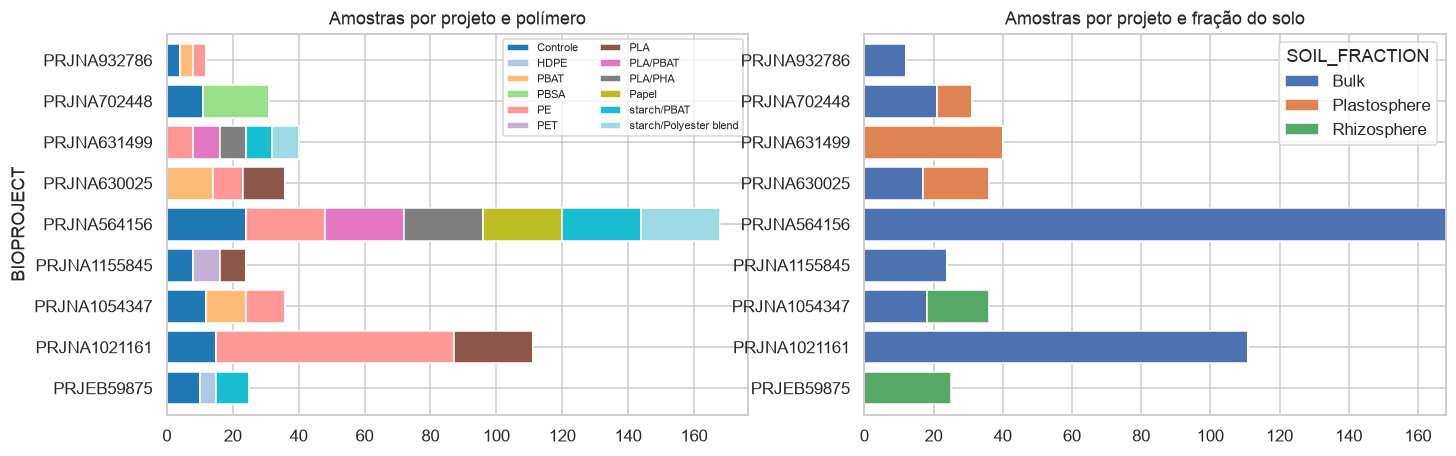

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
pd.crosstab(meta.BIOPROJECT, meta.POLYMER).plot.barh(stacked=True, ax=axes[0], colormap='tab20', width=.8)
axes[0].set_title('Amostras por projeto e polímero'); axes[0].legend(fontsize=7, ncol=2)
pd.crosstab(meta.BIOPROJECT, meta.SOIL_FRACTION).plot.barh(stacked=True, ax=axes[1], width=.8)
axes[1].set_title('Amostras por projeto e fração do solo'); axes[1].set_ylabel('')
savefig('01_desenho_amostral')

**Variáveis de solo.** As variáveis físico‑químicas (pH, SOC, TN, P, K, N mineral…) têm, na prática, **1–6 valores distintos por projeto**
(médias de artigo ou de tratamento), ou seja, estão **confundidas com o estudo**. Elas são usadas apenas de forma descritiva/exploratória.

In [5]:
num = ['pH','SOC(g/kg)','TN(g/kg)','C/N','AP(mg/kg)','AK(mg/kg)','NO3(mg/kg)','NH4(mg/kg)','WATER_CONTENT(%)',
       'ANNUAL_RAINFALL(mm)','AVG_ANNUAL_TEMPERATURE']
solo = meta.groupby('BIOPROJECT')[num].agg(lambda s: f'{s.mean():.3g} ({s.nunique()})' if s.notna().any() else '–')
solo.to_csv(TAB / '01_solo_por_projeto.csv'); solo

,pH,SOC(g/kg),TN(g/kg),C/N,AP(mg/kg),AK(mg/kg),NO3(mg/kg),NH4(mg/kg),WATER_CONTENT(%),ANNUAL_RAINFALL(mm),AVG_ANNUAL_TEMPERATURE
BIOPROJECT,,,,,,,,,,,
PRJEB59875,8.8 (1),–,–,–,–,–,–,–,–,910 (1),14.6 (1)
PRJNA1021161,7.8 (1),6.18 (1),0.81 (1),7.63 (1),4.18 (1),102 (1),–,–,–,584 (1),9.1 (1)
PRJNA1054347,7.76 (6),8.15 (6),1.06 (4),7.84 (6),17.8 (6),216 (5),63.4 (6),4.69 (6),10.9 (6),584 (1),9.1 (1)
PRJNA1155845,–,6.74 (5),–,–,6.24 (6),–,4.21 (5),0.372 (5),55 (1),1.45e+03 (1),17 (1)
PRJNA564156,6.13 (2),23.3 (1),1.54 (1),15.1 (1),5.31 (1),78.4 (1),19.9 (1),4.15 (1),–,1.04e+03 (2),12.2 (2)
PRJNA630025,5.8 (2),70.1 (2),3.7 (2),16.4 (2),–,–,–,–,28 (2),739 (2),-7.75 (2)
PRJNA631499,6.14 (2),23.3 (1),1.54 (1),15.1 (1),5.31 (1),78.4 (1),19.9 (1),4.15 (1),–,1.04e+03 (2),12.2 (2)
PRJNA702448,–,20 (1),–,10 (1),–,–,–,–,60 (1),404 (1),9.8 (1)
PRJNA932786,5.5 (1),29.5 (1),–,–,–,–,–,–,20 (1),1.44e+03 (1),10.3 (1)


## 2. Controle de qualidade e rarefação

ASVs removidos (cloroplasto/mitocôndria/não atribuídos): 0  (0.00% das leituras)
(a taxonomy.tsv tem 49459 ASVs, a tabela 47190: contaminantes já tinham sido removidos no pipeline)


leituras                  ASVs             
                  min  median     max   min median   max
projeto                                                 
PRJEB59875      41303   64963  112037  1242   1638  1957
PRJNA1021161    28408   45214   75835   663   1241  1862
PRJNA1054347    25571   56665   64778  1052   1748  1905
PRJNA1155845    33766   42058   54009   239    782  1057
PRJNA564156     33066   58926  139395  1263   1808  2963
PRJNA630025     12018   26200   81615   171    405   669
PRJNA631499    134561  182848  246091   485    745  1718
PRJNA702448     21674   32971   45104    34    488   826
PRJNA932786     66402   96914  125184  1972   2441  2894

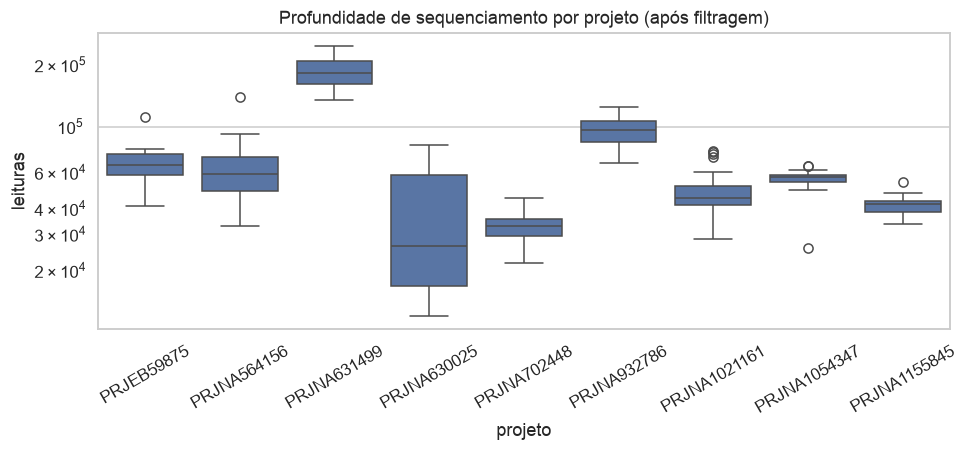

In [6]:
tax_full_n = len(tax); tax = tax.reindex(asv.index)
remover = (tax.Kingdom.isin(['Unassigned']) | tax.Kingdom.isna() |
           tax.Order.eq('Chloroplast') | tax.Family.eq('Mitochondria'))
print(f'ASVs removidos (cloroplasto/mitocôndria/não atribuídos): {remover.sum()}  '
      f'({asv[remover].sum().sum() / asv.values.sum():.2%} das leituras)')
print(f'(a taxonomy.tsv tem {tax_full_n} ASVs, a tabela {asv.shape[0]}: contaminantes já tinham sido removidos no pipeline)')
counts = asv.loc[~remover].astype(int)
tax = tax.loc[counts.index]
depth = counts.sum()
qc = pd.DataFrame({'leituras': depth, 'ASVs': (counts > 0).sum(), 'projeto': meta.BIOPROJECT})
display(qc.groupby('projeto').agg(['min','median','max']).astype(int))

fig, ax = plt.subplots(figsize=(10, 3.5))
sns.boxplot(data=qc, x='projeto', y='leituras', ax=ax); ax.set_yscale('log'); ax.tick_params(axis='x', rotation=30)
ax.set_title('Profundidade de sequenciamento por projeto (após filtragem)'); savefig('02_profundidade')

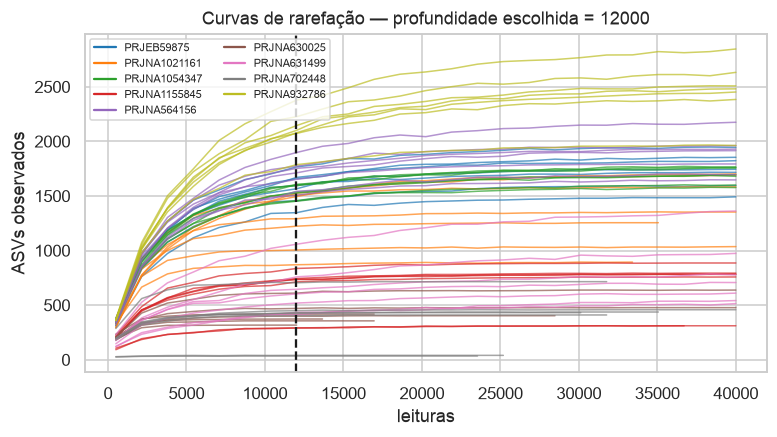

Tabela rarefeita: (46718, 483)


In [7]:
# Curvas de rarefação (subamostra de 60 amostras)
def rarefy_vec(v, d, rng=RNG):
    return rng.multivariate_hypergeometric(v, d) if v.sum() > d else v.copy()

pts = np.unique(np.linspace(500, 40000, 25).astype(int))
sub = qc.groupby('projeto').sample(7, random_state=1, replace=False).index
fig, ax = plt.subplots(figsize=(8, 4))
pal = dict(zip(sorted(meta.BIOPROJECT.unique()), sns.color_palette('tab10', 9)))
for s in sub:
    v = counts[s].values; ys = [(rarefy_vec(v, d) > 0).sum() if d <= v.sum() else np.nan for d in pts]
    ax.plot(pts, ys, color=pal[meta.at[s, 'BIOPROJECT']], alpha=.7, lw=1)
DEPTH = int(np.floor(depth.min() / 1000) * 1000)
ax.axvline(DEPTH, ls='--', c='k'); ax.set_xlabel('leituras'); ax.set_ylabel('ASVs observados')
ax.legend(handles=[plt.Line2D([], [], color=c, label=k) for k, c in pal.items()], fontsize=7, ncol=2)
ax.set_title(f'Curvas de rarefação — profundidade escolhida = {DEPTH}'); savefig('02_rarefacao')

rare = pd.DataFrame(np.column_stack([rarefy_vec(counts[s].values, DEPTH) for s in counts.columns]),
                    index=counts.index, columns=counts.columns)
rare = rare.loc[rare.sum(1) > 0]
print('Tabela rarefeita:', rare.shape)

## 3. Composição taxonômica

In [8]:
def lowest(row):
    for r in ['Genus','Family','Order','Class','Phylum']:
        if pd.notna(row[r]): return row[r] if r == 'Genus' else f'{row[r]} (NC)'
    return 'Não classificado'
tax['LABEL'] = tax.apply(lowest, axis=1)
rel = counts / counts.sum()
phy = rel.groupby(tax.Phylum.fillna('Não classificado')).sum()
gen = rel.groupby(tax.LABEL).sum()

top_phy = phy.mean(1).sort_values(ascending=False).head(12).index
print('Filos mais abundantes (média global, %):'); display((phy.loc[top_phy].mean(1) * 100).round(2).to_frame('%'))
(phy * 100).T.groupby(meta.BIOPROJECT).mean().T.round(2).to_csv(TAB / '03_filos_por_projeto.csv')

Filos mais abundantes (média global, %):


,%
Phylum,
Proteobacteria,25.87
Acidobacteriota,13.47
Actinobacteriota,12.14
Chloroflexi,9.91
Firmicutes,8.37
Bacteroidota,6.90
Planctomycetota,6.29
Patescibacteria,3.77
Verrucomicrobiota,3.74


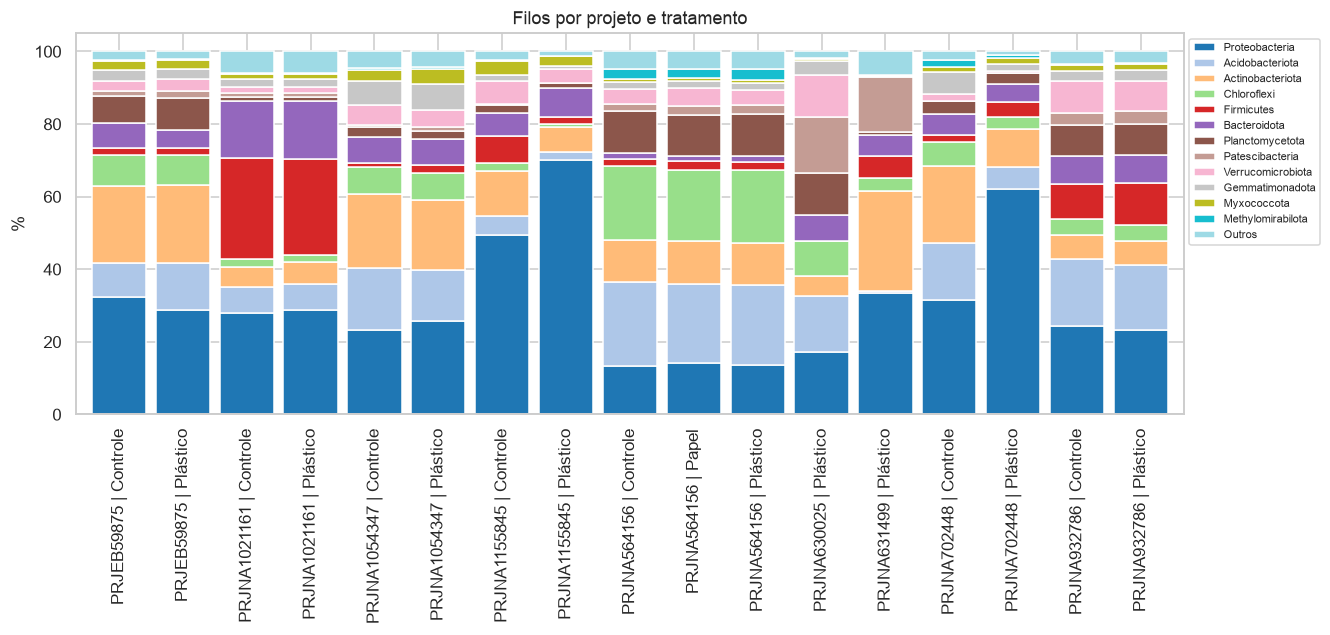

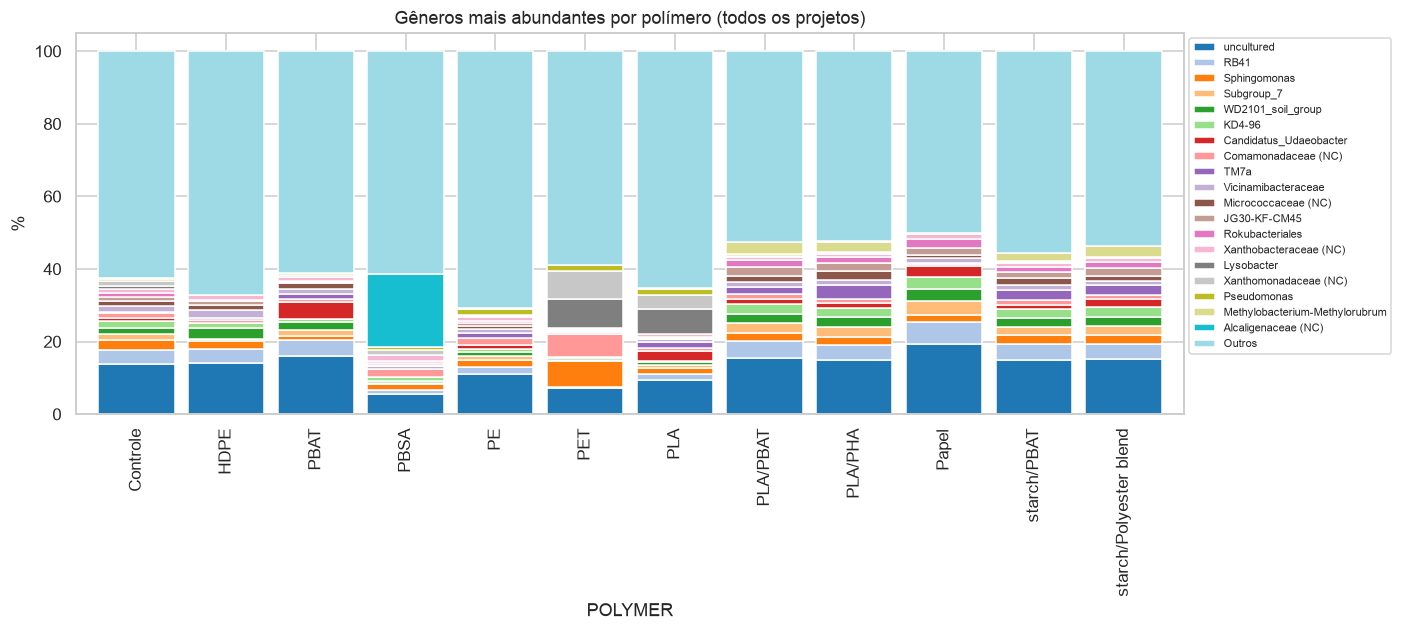

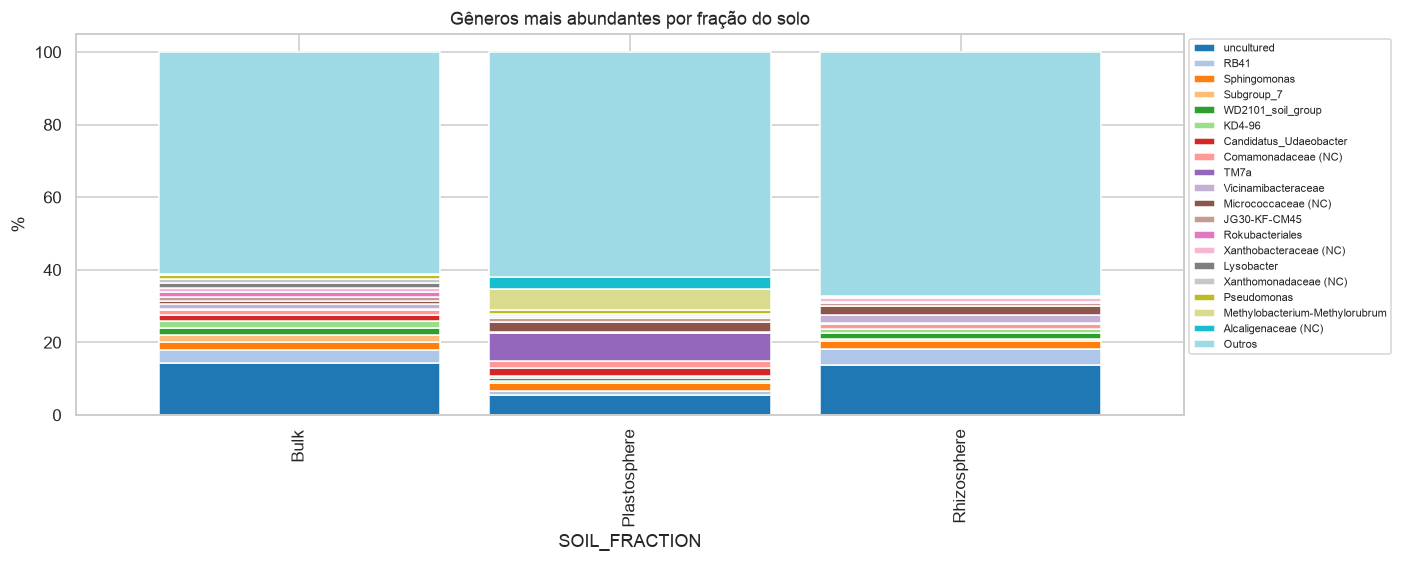

In [9]:
def stacked(df, grp, top, title, name, ax=None):
    d = df.T.groupby(grp).mean().T
    d = pd.concat([d.loc[top], (1 - d.loc[top].sum()).to_frame('Outros').T]) * 100
    ax = d.T.plot.bar(stacked=True, figsize=(13, 4.5), width=.85, colormap='tab20', ax=ax)
    ax.legend(bbox_to_anchor=(1, 1), fontsize=7); ax.set_ylabel('%'); ax.set_title(title)
    savefig(name)

g = meta.BIOPROJECT + ' | ' + meta.TRAT
stacked(phy, g, top_phy, 'Filos por projeto e tratamento', '03_filos_projeto_trat')
top_gen = gen.mean(1).sort_values(ascending=False).head(19).index
stacked(gen, meta.POLYMER, top_gen, 'Gêneros mais abundantes por polímero (todos os projetos)', '03_generos_polimero')
stacked(gen, meta.SOIL_FRACTION, top_gen, 'Gêneros mais abundantes por fração do solo', '03_generos_fracao')

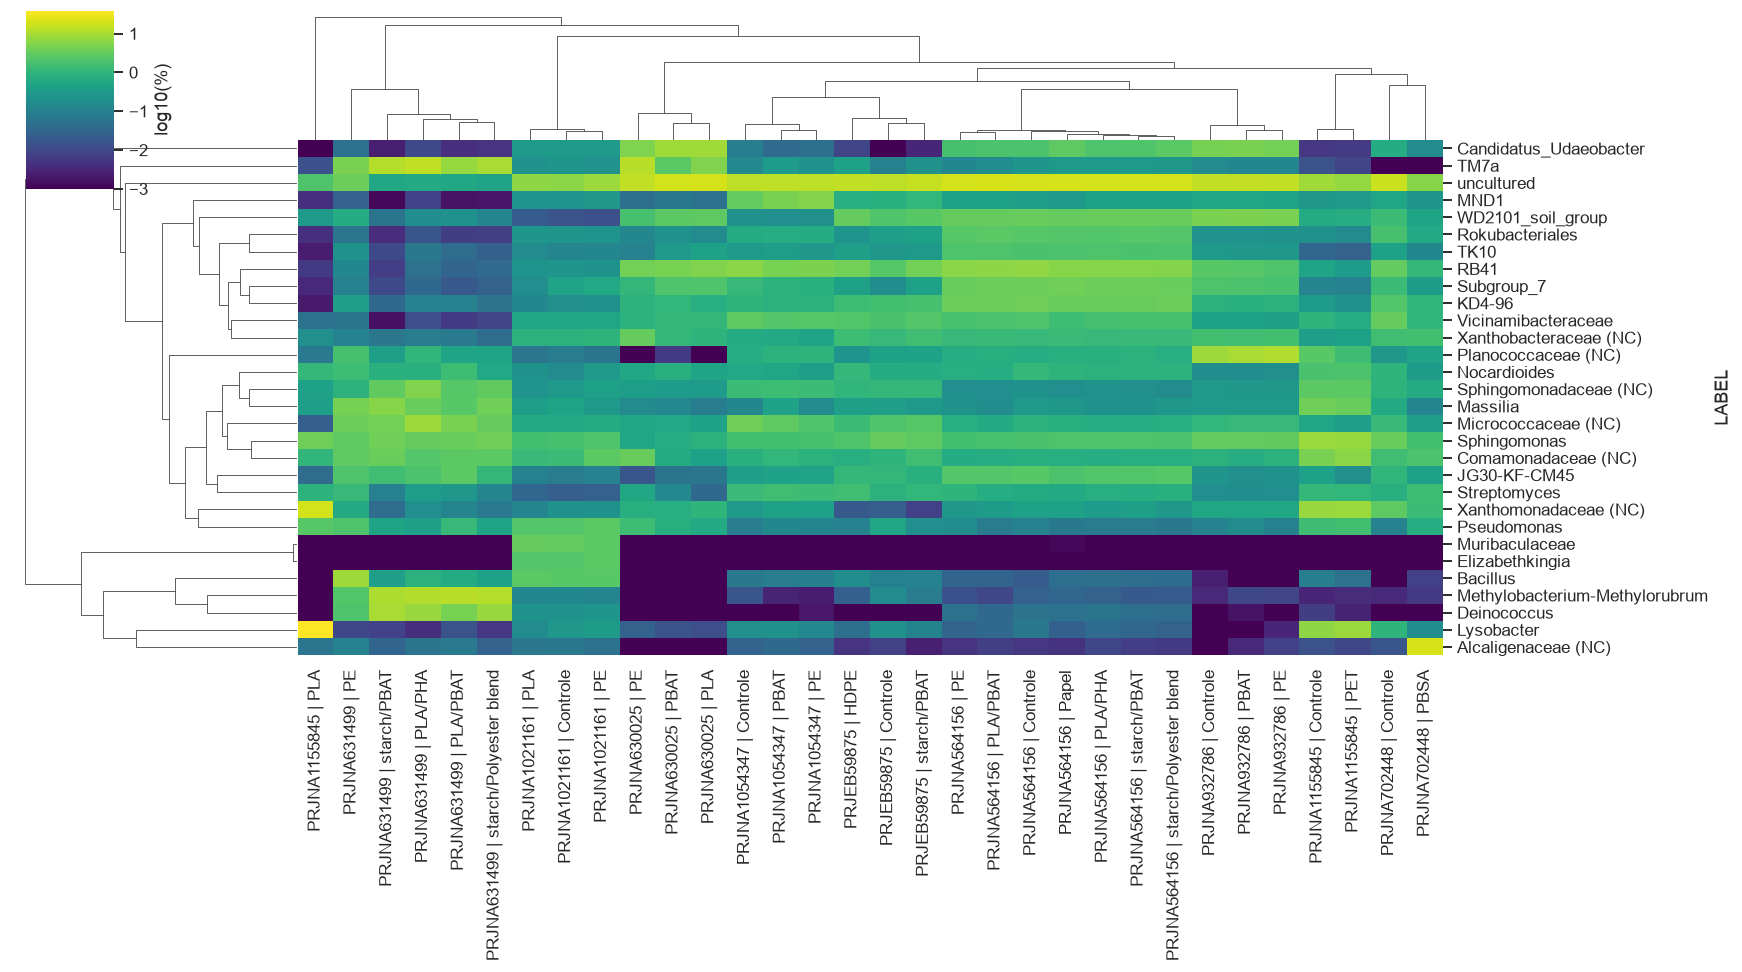

In [10]:
# Heatmap dos 30 gêneros mais abundantes: média por projeto × tratamento (z-score por gênero sobre log10)
top30 = gen.mean(1).sort_values(ascending=False).head(30).index
h = np.log10(gen.loc[top30].T.groupby(meta.BIOPROJECT + ' | ' + meta.POLYMER).mean().T * 100 + 1e-3)
sns.clustermap(h, cmap='viridis', figsize=(16, 9), col_cluster=True, row_cluster=True,
               cbar_kws={'label': 'log10(%)'}, xticklabels=True, yticklabels=True)
plt.savefig(FIG / '03_heatmap_generos.png', dpi=150); plt.show()

## 4. Diversidade alfa

Métricas em tabela rarefeita (profundidade única): riqueza observada, Shannon, Simpson, equitabilidade de Pielou e
**Faith PD** (filogenética, usando `tree.nwk`).

In [11]:
ids = list(rare.columns); M = rare.T.values; taxa = list(rare.index)
alpha = pd.DataFrame({
    'Riqueza': alpha_diversity('observed_features', M, ids),
    'Shannon': alpha_diversity('shannon', M, ids),
    'Simpson': alpha_diversity('simpson', M, ids),
    'Pielou': alpha_diversity('pielou_e', M, ids),
    'FaithPD': alpha_diversity('faith_pd', M, ids, taxa=taxa, tree=tree, validate=False),
})
A = alpha.join(meta)
A[list(alpha.columns) + ['BIOPROJECT','POLYMER','TRAT','CLASSE','SOIL_FRACTION']].to_csv(TAB / '04_alfa_por_amostra.csv')
A.groupby(['BIOPROJECT','TRAT'])[list(alpha.columns)].median().round(2)

Riqueza  Shannon  Simpson  Pielou  FaithPD
BIOPROJECT   TRAT                                                
PRJEB59875   Controle   1396.0     6.64     1.00    0.91   103.86
             Plástico   1549.0     6.73     1.00    0.92   111.50
PRJNA1021161 Controle   1196.0     6.09     0.99    0.84    96.75
             Plástico   1168.5     6.16     0.99    0.85    95.76
PRJNA1054347 Controle   1541.5     6.67     1.00    0.91    98.58
             Plástico   1586.5     6.76     1.00    0.92    99.18
PRJNA1155845 Controle    845.0     5.56     0.99    0.82    65.04
             Plástico    490.5     4.42     0.96    0.72    43.49
PRJNA564156  Controle   1726.0     6.81     1.00    0.92   111.23
             Papel      1617.5     6.75     1.00    0.91   108.41
             Plástico   1660.0     6.77     1.00    0.91   111.03
PRJNA630025  Plástico    403.5     5.18     0.98    0.82    47.76
PRJNA631499  Plástico    586.5     4.73     0.98    0.75    36.72
PRJNA702448  Controle    729.0     6.14     1.00    0.93    62.21
             Plástico    380.5     4.81     0.96    0.80    39.71
PRJNA932786  Controle   1989.0     6.80     0.99    0.90   122.66
             Plástico   2110.5     6.73     0.99    0.88   128.41

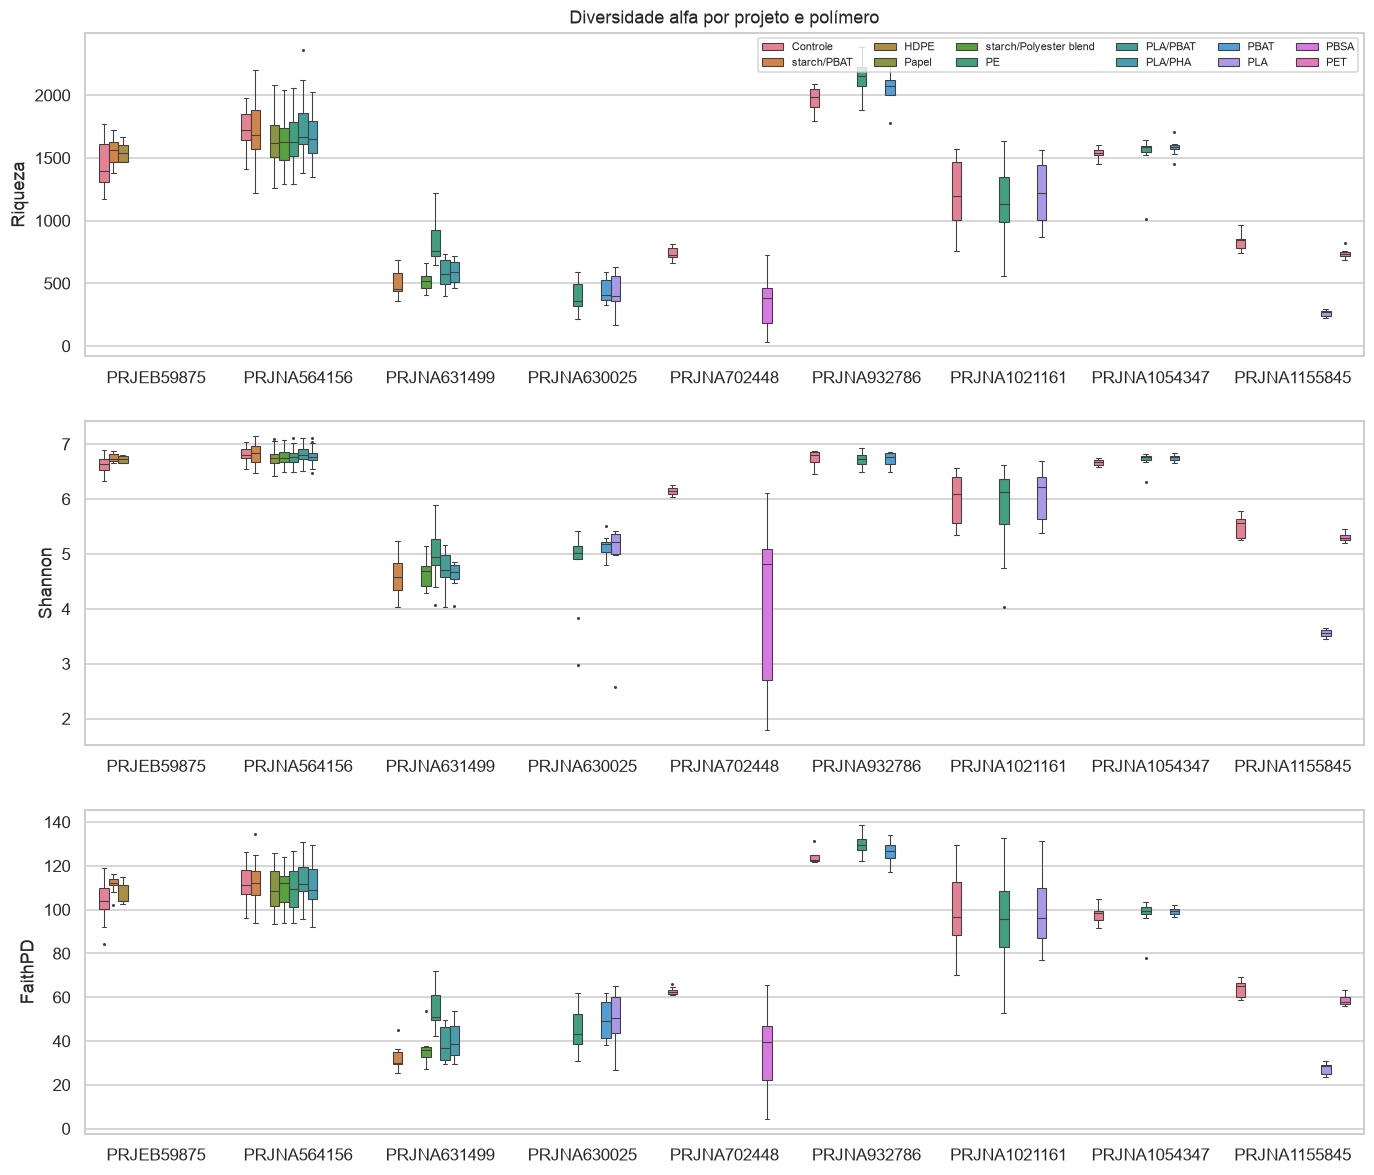

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(15, 13))
for ax, mt in zip(axes, ['Riqueza','Shannon','FaithPD']):
    sns.boxplot(data=A, x='BIOPROJECT', y=mt, hue='POLYMER', ax=ax, fliersize=1, linewidth=.7)
    ax.legend(fontsize=7, ncol=6, loc='upper right') if mt == 'Riqueza' else ax.get_legend().remove()
    ax.set_xlabel('')
axes[0].set_title('Diversidade alfa por projeto e polímero'); savefig('04_alfa_boxplot')

### 4.1 Plástico × controle dentro de cada estudo + meta-análise

Para cada **estrato = projeto × fração do solo** que tenha plástico e controle (evita comparar plastisfera com solo sem plástico):
Mann‑Whitney e efeito padronizado (Hedges g, plástico − controle). Como sensibilidade, repetimos agrupando só por projeto.
Os g são combinados por **meta‑análise de efeitos aleatórios (DerSimonian‑Laird)**. Também ajustamos um
**modelo linear misto** `métrica ~ CLASSE + fração + (1 | projeto)`.

In [13]:
def hedges_g(x, y):
    nx, ny = len(x), len(y)
    sp = np.sqrt(((nx - 1) * np.var(x, ddof=1) + (ny - 1) * np.var(y, ddof=1)) / (nx + ny - 2))
    d = (np.mean(x) - np.mean(y)) / sp; J = 1 - 3 / (4 * (nx + ny) - 9); g = J * d
    return g, (nx + ny) / (nx * ny) + g ** 2 / (2 * (nx + ny))

def dersimonian_laird(g, v):
    g, v = np.asarray(g), np.asarray(v); w = 1 / v
    fe = (w * g).sum() / w.sum(); Q = (w * (g - fe) ** 2).sum(); k = len(g)
    tau2 = max(0, (Q - (k - 1)) / (w.sum() - (w ** 2).sum() / w.sum()))
    ws = 1 / (v + tau2); mu = (ws * g).sum() / ws.sum(); se = np.sqrt(1 / ws.sum())
    I2 = max(0, (Q - (k - 1)) / Q) if Q > 0 else 0
    return mu, se, 2 * stats.norm.sf(abs(mu / se)), tau2, I2

def efeitos(A, alvo, ref='Controle', col='CLASSE', metricas=('Riqueza','Shannon','FaithPD','Pielou'), por='ESTRATO'):
    rows = []
    for pj, d in A.groupby(por):
        x, y = d[d[col].isin(alvo)], d[d[col].eq(ref)]
        if len(x) < 3 or len(y) < 3: continue
        for mt in metricas:
            g, v = hedges_g(x[mt].values, y[mt].values)
            rows.append(dict(projeto=pj, metrica=mt, n_plast=len(x), n_ctrl=len(y), g=g, var=v,
                             p_MW=stats.mannwhitneyu(x[mt], y[mt]).pvalue))
    return pd.DataFrame(rows)

ef = efeitos(A, ['Biodegradável', 'Não biodegradável'])
ef['q_MW'] = multipletests(ef.p_MW, method='fdr_bh')[1]
ef.round(3).to_csv(TAB / '04_alfa_efeito_por_projeto.csv')
display(ef.pivot(index='projeto', columns='metrica', values='g').round(2))

meta_rows = []
for classe, alvo in [('Plástico (todos)', ['Biodegradável','Não biodegradável']),
                     ('Biodegradável', ['Biodegradável']), ('Não biodegradável', ['Não biodegradável'])]:
    e = efeitos(A, alvo)
    for mt, d in e.groupby('metrica'):
        mu, se, p, tau2, I2 = dersimonian_laird(d.g, d['var'])
        meta_rows.append(dict(comparacao=classe + ' vs Controle', metrica=mt, k_estudos=len(d),
                              g=mu, IC95_inf=mu - 1.96 * se, IC95_sup=mu + 1.96 * se, p=p, I2=I2))
for mt, d in efeitos(A, ['Biodegradável','Não biodegradável'], por='BIOPROJECT').groupby('metrica'):
    mu, se, p, tau2, I2 = dersimonian_laird(d.g, d['var'])
    meta_rows.append(dict(comparacao='[sensib.] Plástico vs Controle, por projeto (ignora fração)', metrica=mt, k_estudos=len(d),
                          g=mu, IC95_inf=mu - 1.96 * se, IC95_sup=mu + 1.96 * se, p=p, I2=I2))
MA = pd.DataFrame(meta_rows); MA.round(3).to_csv(TAB / '04_alfa_metaanalise.csv'); MA.round(3)

metrica,FaithPD,Pielou,Riqueza,Shannon
projeto,,,,
PRJEB59875 | Rhizosphere,0.83,0.60,0.74,0.94
PRJNA1021161 | Bulk,-0.06,-0.00,-0.09,-0.02
PRJNA1054347 | Bulk,-0.17,2.04,1.09,2.42
PRJNA1054347 | Rhizosphere,0.35,3.08,-0.01,0.52
PRJNA1155845 | Bulk,-1.46,-1.31,-1.54,-1.36
PRJNA564156 | Bulk,-0.13,0.12,-0.23,-0.13
PRJNA702448 | Bulk,-1.33,-1.25,-1.77,-1.44
PRJNA932786 | Bulk,0.54,-0.45,0.67,-0.07


,comparacao,metrica,k_estudos,g,IC95_inf,IC95_sup,p,I2
0,Plástico (todos) vs Controle,FaithPD,8,-0.179,-0.665,0.308,0.472,0.667
1,Plástico (todos) vs Controle,Pielou,8,0.264,-0.483,1.010,0.489,0.850
2,Plástico (todos) vs Controle,Riqueza,8,-0.155,-0.740,0.430,0.603,0.766
3,Plástico (todos) vs Controle,Shannon,8,0.058,-0.598,0.714,0.864,0.812
4,Biodegradável vs Controle,FaithPD,8,-0.296,-1.168,0.577,0.506,0.851
5,Biodegradável vs Controle,Pielou,8,-0.048,-1.028,0.931,0.923,0.875
6,Biodegradável vs Controle,Riqueza,8,-0.310,-1.223,0.604,0.506,0.863
7,Biodegradável vs Controle,Shannon,8,-0.042,-1.074,0.990,0.937,0.886
8,Não biodegradável vs Controle,FaithPD,7,-0.166,-0.565,0.233,0.415,0.279
9,Não biodegradável vs Controle,Pielou,7,0.435,-0.323,1.192,0.261,0.768


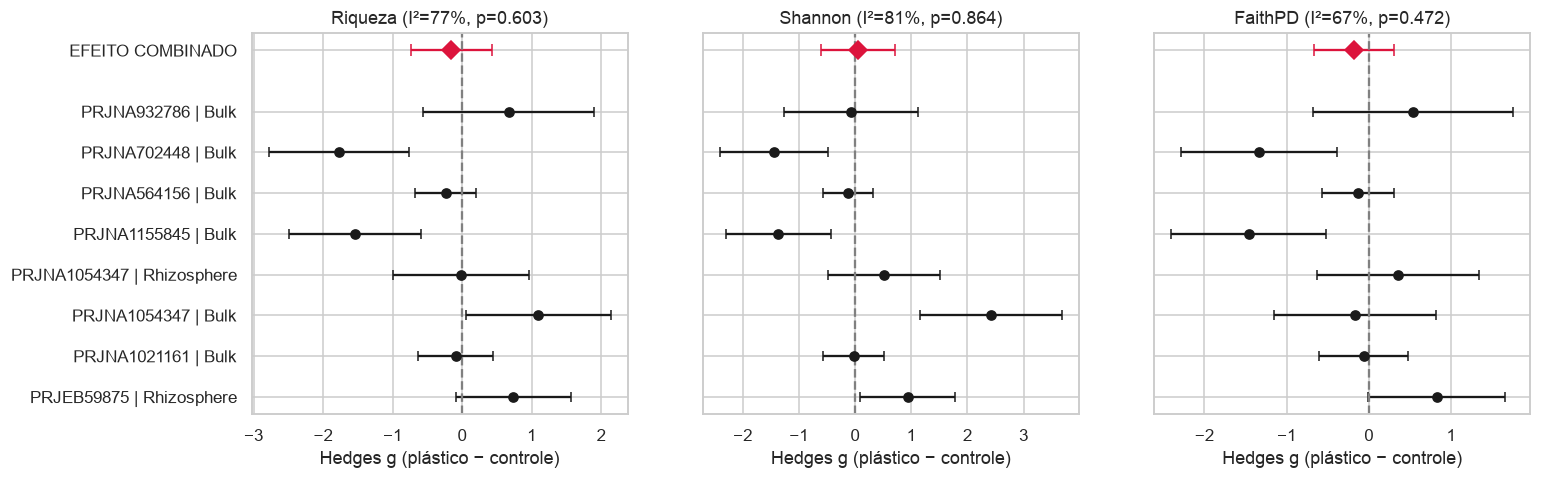

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, mt in zip(axes, ['Riqueza','Shannon','FaithPD']):
    d = ef[ef.metrica == mt].reset_index(drop=True); se = np.sqrt(d['var'])
    ax.errorbar(d.g, range(len(d)), xerr=1.96 * se, fmt='o', c='k', capsize=3)
    r = MA[(MA.metrica == mt) & (MA.comparacao == 'Plástico (todos) vs Controle')].iloc[0]
    ax.errorbar(r.g, len(d) + .5, xerr=[[r.g - r.IC95_inf], [r.IC95_sup - r.g]], fmt='D', c='crimson', capsize=4, ms=8)
    ax.axvline(0, ls='--', c='grey'); ax.set_title(f'{mt} (I²={r.I2:.0%}, p={r.p:.3f})'); ax.set_xlabel('Hedges g (plástico − controle)')
    ax.set_yticks(list(range(len(d))) + [len(d) + .5], list(d.projeto) + ['EFEITO COMBINADO'])
savefig('04_alfa_forest')

In [15]:
res = []
sub = A[A.ESTRATO.isin(ef.projeto.unique()) & A.CLASSE.ne('Papel')].copy()
sub['CLASSE'] = pd.Categorical(sub.CLASSE, ['Controle','Biodegradável','Não biodegradável'])
for mt in ['Riqueza','Shannon','FaithPD','Pielou']:
    sub['y'] = (sub[mt] - sub[mt].mean()) / sub[mt].std()
    fit = smf.mixedlm('y ~ CLASSE + SOIL_FRACTION', sub, groups=sub.BIOPROJECT).fit(reml=True)
    for term in fit.params.index:
        if term.startswith('CLASSE') or term.startswith('SOIL'):
            res.append(dict(metrica=mt, termo=term, coef_z=fit.params[term], p=fit.pvalues[term]))
LMM = pd.DataFrame(res); LMM.round(4).to_csv(TAB / '04_alfa_modelo_misto.csv'); LMM.round(4)

,metrica,termo,coef_z,p
0,Riqueza,CLASSE[T.Biodegradável],-0.1368,0.0449
1,Riqueza,CLASSE[T.Não biodegradável],-0.1132,0.1290
2,Riqueza,SOIL_FRACTION[T.Rhizosphere],-0.1628,0.3158
3,Shannon,CLASSE[T.Biodegradável],-0.3256,0.0001
4,Shannon,CLASSE[T.Não biodegradável],-0.1649,0.0668
5,Shannon,SOIL_FRACTION[T.Rhizosphere],-0.1116,0.5681
6,FaithPD,CLASSE[T.Biodegradável],-0.1365,0.0798
7,FaithPD,CLASSE[T.Não biodegradável],-0.1183,0.1652
8,FaithPD,SOIL_FRACTION[T.Rhizosphere],-0.1701,0.3584
9,Pielou,CLASSE[T.Biodegradável],-0.3494,0.0004


### 4.2 Diversidade alfa por fração do solo (plastisfera × bulk × rizosfera)

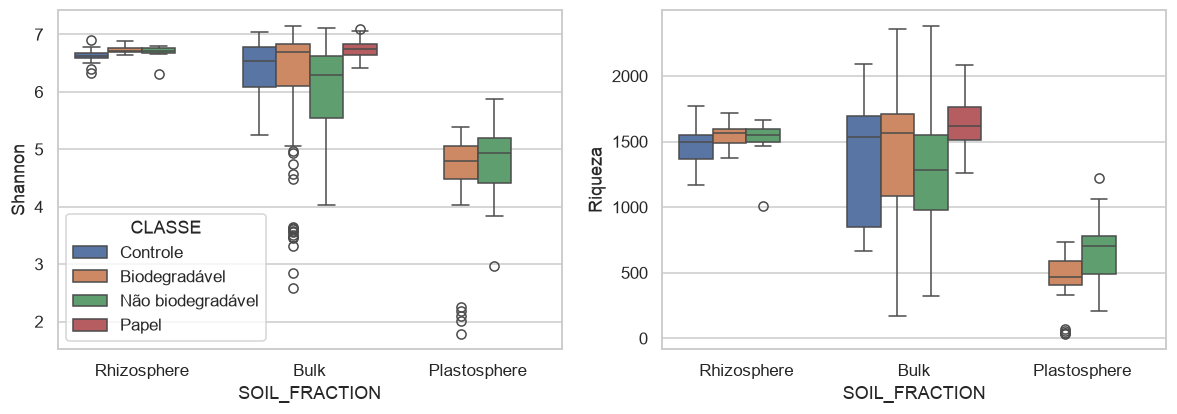

PRJNA630025 Riqueza: plastisfera=404.0  bulk=403.0  p=0.54
PRJNA630025 Shannon: plastisfera=5.1  bulk=5.2  p=0.23
PRJNA630025 FaithPD: plastisfera=49.9  bulk=46.2  p=0.66
EUA 2016-09 Riqueza: plastisfera=586.5 (n=40)  bulk=1672.5 (n=30)  p=1.1e-12
EUA 2016-09 Shannon: plastisfera=4.7 (n=40)  bulk=6.7 (n=30)  p=1.1e-12
EUA 2016-09 FaithPD: plastisfera=36.7 (n=40)  bulk=109.3 (n=30)  p=1.1e-12


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=A, x='SOIL_FRACTION', y='Shannon', hue='CLASSE', ax=ax[0])
sns.boxplot(data=A, x='SOIL_FRACTION', y='Riqueza', hue='CLASSE', ax=ax[1]); ax[1].get_legend().remove()
savefig('04_alfa_fracao')
# Comparação pareada no mesmo desenho: PRJNA630025 (plastisfera vs bulk, mesmos polímeros)
d = A[A.BIOPROJECT == 'PRJNA630025']
for mt in ['Riqueza','Shannon','FaithPD']:
    x, y = d[d.SOIL_FRACTION == 'Plastosphere'][mt], d[d.SOIL_FRACTION == 'Bulk'][mt]
    print(f'PRJNA630025 {mt}: plastisfera={x.median():.1f}  bulk={y.median():.1f}  p={stats.mannwhitneyu(x, y).pvalue:.2g}')
# PRJNA564156 (bulk) x PRJNA631499 (plastisfera) — mesma coleta 2016-09
d = A[A.COLETA.eq('2016-09') & A.TRAT.eq('Plástico')]
for mt in ['Riqueza','Shannon','FaithPD']:
    x, y = d[d.SOIL_FRACTION == 'Plastosphere'][mt], d[d.SOIL_FRACTION == 'Bulk'][mt]
    print(f'EUA 2016-09 {mt}: plastisfera={x.median():.1f} (n={len(x)})  bulk={y.median():.1f} (n={len(y)})  p={stats.mannwhitneyu(x, y).pvalue:.2g}')

## 5. Diversidade beta

### 5.1 Visão global (nível de gênero, compatível entre regiões do 16S)
PERMANOVA sequencial (tipo adonis2 *by terms*) implementada abaixo; para o efeito de tratamento as
permutações são **restritas dentro de cada projeto**.

In [17]:
def _design(meta, terms):
    X = [np.ones((len(meta), 1))]; mats = []; dfs = []
    for t in terms:
        col = meta[t]
        if pd.api.types.is_numeric_dtype(col): col = col.fillna(col.mean())
        else: col = col.astype(object).fillna('NA')
        Xt = (pd.get_dummies(col.astype(str), drop_first=True).values.astype(float)
              if not pd.api.types.is_numeric_dtype(col) else ((col - col.mean()) / col.std()).values[:, None])
        before = np.linalg.matrix_rank(np.hstack(X)); X.append(Xt); M = np.hstack(X)
        dfs.append(np.linalg.matrix_rank(M) - before); mats.append(M @ np.linalg.pinv(M))
    return mats, dfs

def permanova_seq(D, meta, terms, perms=999, strata=None, seed=0):
    '''PERMANOVA sequencial (SS tipo I) com permutação opcional restrita a estratos.'''
    D = np.asarray(D); n = len(D); A_ = -0.5 * D ** 2; J = np.eye(n) - 1 / n; G = J @ A_ @ J; SST = np.trace(G)
    Hs, dfs = _design(meta, terms)
    def stat(Gm):
        tr = [np.sum(H * Gm) for H in Hs]; ss = np.diff([0] + tr); res = SST - tr[-1]
        dfr = n - 1 - sum(dfs); return ss, res, dfr
    ss, res, dfr = stat(G); F = (ss / dfs) / (res / dfr)
    rng = np.random.default_rng(seed); cnt = np.zeros(len(terms))
    groups = [np.arange(n)] if strata is None else [np.where(strata == s)[0] for s in np.unique(strata)]
    for _ in range(perms):
        p = np.arange(n)
        for g in groups: p[g] = rng.permutation(g)
        s2, r2, _ = stat(G[np.ix_(p, p)]); cnt += ((s2 / dfs) / (r2 / dfr)) >= F - 1e-12
    out = pd.DataFrame({'gl': dfs, 'SS': ss, 'R2': ss / SST, 'F': F, 'p': (cnt + 1) / (perms + 1)}, index=terms)
    out.loc['Residual'] = [dfr, res, res / SST, np.nan, np.nan]
    return out

def betadisper_test(D, groups):
    '''PERMDISP simples: distância ao centróide (PCoA) + ANOVA/Kruskal.'''
    o = pcoa(skbio.DistanceMatrix(D, ids=[str(i) for i in range(len(D))]), method='eigh')
    X = o.samples.values[:, o.eigvals.values > 0]
    dist = np.zeros(len(D)); groups = np.asarray(groups)
    for g in np.unique(groups):
        idx = groups == g; dist[idx] = np.linalg.norm(X[idx] - X[idx].mean(0), axis=1)
    return pd.Series(dist), stats.kruskal(*[dist[groups == g] for g in np.unique(groups)]).pvalue

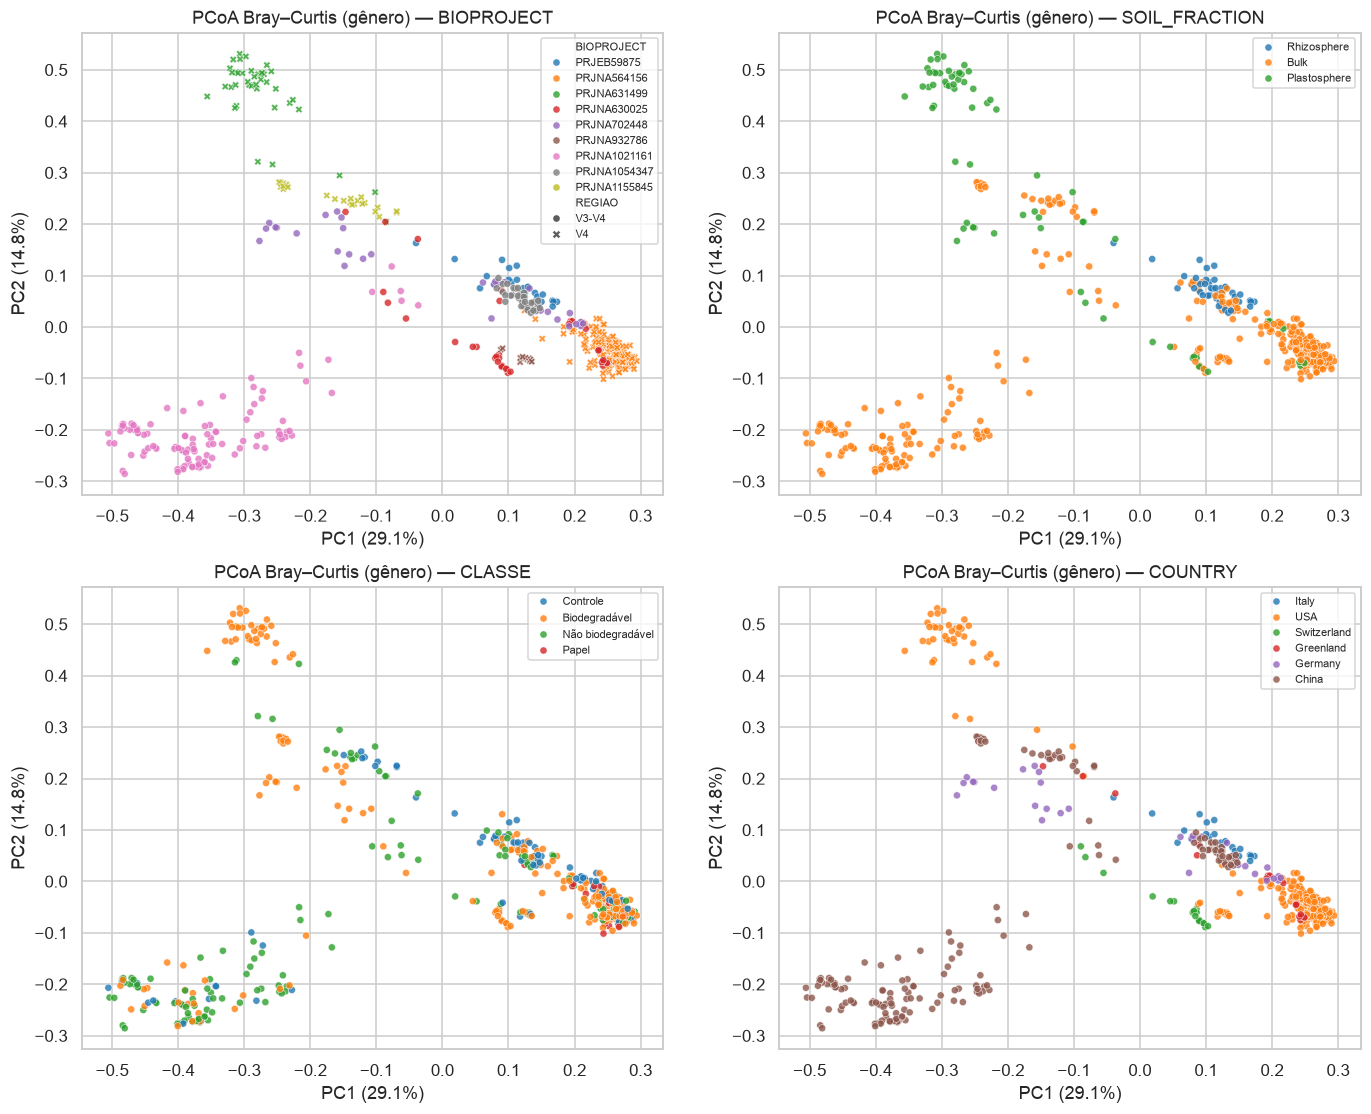

In [18]:
gen_rel = rel.groupby(tax.LABEL).sum()
gen_rel = gen_rel.loc[(gen_rel > 0.0001).sum(1) >= 5]           # gêneros presentes em ≥5 amostras
bc_gen = beta_diversity('braycurtis', gen_rel.T.values, ids=list(gen_rel.columns))
ord_g = pcoa(bc_gen, number_of_dimensions=5)
PC = ord_g.samples.iloc[:, :3].set_axis(['PC1','PC2','PC3'], axis=1); PC.index = gen_rel.columns
PC = PC.join(meta)
ve = ord_g.proportion_explained.values[:2] * 100

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, (hue, st) in zip(axes.flat, [('BIOPROJECT', 'REGIAO'), ('SOIL_FRACTION', None), ('CLASSE', None), ('COUNTRY', None)]):
    sns.scatterplot(data=PC, x='PC1', y='PC2', hue=hue, style=st, s=22, ax=ax, alpha=.8, palette='tab10')
    ax.set_xlabel(f'PC1 ({ve[0]:.1f}%)'); ax.set_ylabel(f'PC2 ({ve[1]:.1f}%)'); ax.legend(fontsize=7); ax.set_title(f'PCoA Bray–Curtis (gênero) — {hue}')
savefig('05_pcoa_global')

In [19]:
D = bc_gen.data; mt_ = meta.loc[gen_rel.columns]
glob = permanova_seq(D, mt_, ['REGIAO', 'BIOPROJECT', 'SOIL_FRACTION', 'CLASSE'], perms=499)
print('PERMANOVA global (Bray–Curtis, gênero), termos sequenciais — permutação livre'); display(glob.round(4))
glob.to_csv(TAB / '05_permanova_global.csv')

# efeito do tratamento, controlando por projeto e fração, com permutação restrita ao projeto
com_ctrl = mt_.groupby('BIOPROJECT').CLASSE.transform(lambda s: (s == 'Controle').any() and (s != 'Controle').any())
idx = np.where(com_ctrl)[0]
glob2 = permanova_seq(D[np.ix_(idx, idx)], mt_.iloc[idx], ['BIOPROJECT', 'SOIL_FRACTION', 'CLASSE'],
                      perms=499, strata=mt_.BIOPROJECT.values[idx])
print('Somente projetos com controle; permutações restritas ao projeto'); display(glob2.round(4))
glob2.to_csv(TAB / '05_permanova_global_estratificada.csv')

PERMANOVA global (Bray–Curtis, gênero), termos sequenciais — permutação livre


,gl,SS,R2,F,p
REGIAO,1.0,13.0553,0.1157,149.5834,0.002
BIOPROJECT,7.0,56.9463,0.5047,93.2105,0.002
SOIL_FRACTION,2.0,1.2750,0.0113,7.3045,0.002
CLASSE,3.0,0.6113,0.0054,2.3346,0.004
Residual,469.0,40.9332,0.3628,NaN,NaN


Somente projetos com controle; permutações restritas ao projeto


,gl,SS,R2,F,p
BIOPROJECT,6.0,50.3409,0.6079,111.4573,0.002
SOIL_FRACTION,2.0,2.2877,0.0276,15.1952,0.002
CLASSE,3.0,0.4465,0.0054,1.9770,0.002
Residual,395.0,29.7343,0.3591,NaN,NaN


### 5.2 Dentro de cada projeto (nível de ASV, tabela rarefeita)
Bray–Curtis (abundância) e UniFrac ponderado (filogenético). Termos específicos de cada desenho experimental.

In [20]:
desenhos = {
    'PRJNA1054347': ['SOIL_FRACTION', 'POLYMER'],
    'PRJNA1021161': ['DIAS', 'POLYMER', 'DOSE', 'ENVELHECIMENTO'],
    'PRJNA1155845': ['GLIFOSATO', 'POLYMER'],
    'PRJNA564156':  ['SITIO', 'COLETA', 'POLYMER'],
    'PRJNA631499':  ['SITIO', 'POLYMER'],
    'PRJNA630025':  ['SITIO', 'SOIL_FRACTION', 'POLYMER'],
    'PRJNA702448':  ['NITROGENIO', 'SOIL_FRACTION', 'TRAT'],
    'PRJEB59875':   ['CULTIVAR', 'POLYMER'],
    'PRJNA932786':  ['POLYMER'],
}
perm_rows, disp_rows, ords = [], [], {}
for pj, terms in desenhos.items():
    s = meta.index[meta.BIOPROJECT == pj]; X = rare[s]; X = X.loc[X.sum(1) > 0]
    mm = meta.loc[s].copy()
    for t in terms:
        if mm[t].dtype == object or str(mm[t].dtype).startswith('str'): mm[t] = mm[t].fillna('NA')
    for metric in ['braycurtis', 'weighted_unifrac']:
        kw = dict(taxa=list(X.index), tree=tree, validate=False) if 'unifrac' in metric else {}
        dm = beta_diversity(metric, X.T.values, ids=list(s), **kw)
        if metric == 'braycurtis': ords[pj] = (pcoa(dm, number_of_dimensions=3), mm)
        r = permanova_seq(dm.data, mm, terms, perms=999)
        for t, row in r.drop('Residual').iterrows():
            perm_rows.append(dict(projeto=pj, metrica=metric, termo=t, gl=row.gl, R2=row.R2, F=row.F, p=row.p))
        if metric == 'braycurtis':
            _, pdisp = betadisper_test(dm.data, mm.TRAT if mm.TRAT.nunique() > 1 else mm.POLYMER)
            disp_rows.append(dict(projeto=pj, grupos='TRAT' if mm.TRAT.nunique() > 1 else 'POLYMER', p_dispersao=pdisp))
PP = pd.DataFrame(perm_rows); PP.round(4).to_csv(TAB / '05_permanova_por_projeto.csv', index=False)
display(PP.pivot_table(index=['projeto','termo'], columns='metrica', values=['R2','p']).round(3))
pd.DataFrame(disp_rows).round(4)

R2                           p                 
metrica                     braycurtis weighted_unifrac braycurtis weighted_unifrac
projeto      termo                                                                 
PRJEB59875   CULTIVAR            0.084            0.112      0.002            0.003
             POLYMER             0.105            0.158      0.057            0.007
PRJNA1021161 DIAS                0.019            0.011      0.018            0.245
             DOSE                0.009            0.009      0.355            0.377
             ENVELHECIMENTO      0.033            0.047      0.018            0.005
             POLYMER             0.019            0.018      0.316            0.391
PRJNA1054347 POLYMER             0.159            0.201      0.001            0.001
             SOIL_FRACTION       0.110            0.155      0.001            0.001
PRJNA1155845 GLIFOSATO           0.019            0.015      0.166            0.125
             POLYMER             0.825            0.879      0.001            0.001
PRJNA564156  COLETA              0.067            0.187      0.001            0.001
             POLYMER             0.033            0.028      0.005            0.021
             SITIO               0.446            0.367      0.001            0.001
PRJNA630025  POLYMER             0.042            0.060      0.076            0.027
             SITIO               0.639            0.551      0.001            0.001
             SOIL_FRACTION       0.012            0.015      0.243            0.269
PRJNA631499  POLYMER             0.157            0.256      0.001            0.001
             SITIO               0.351            0.325      0.001            0.001
PRJNA702448  NITROGENIO          0.201            0.282      0.001            0.001
             SOIL_FRACTION       0.241            0.241      0.001            0.001
             TRAT                0.081            0.079      0.003            0.005
PRJNA932786  POLYMER             0.182            0.172      0.426            0.522

,projeto,grupos,p_dispersao
0,PRJNA1054347,TRAT,0.0000
1,PRJNA1021161,TRAT,0.4582
2,PRJNA1155845,TRAT,0.0001
3,PRJNA564156,TRAT,0.1702
4,PRJNA631499,POLYMER,0.0001
5,PRJNA630025,POLYMER,0.5491
6,PRJNA702448,TRAT,0.0000
7,PRJEB59875,TRAT,0.0855
8,PRJNA932786,TRAT,0.8651


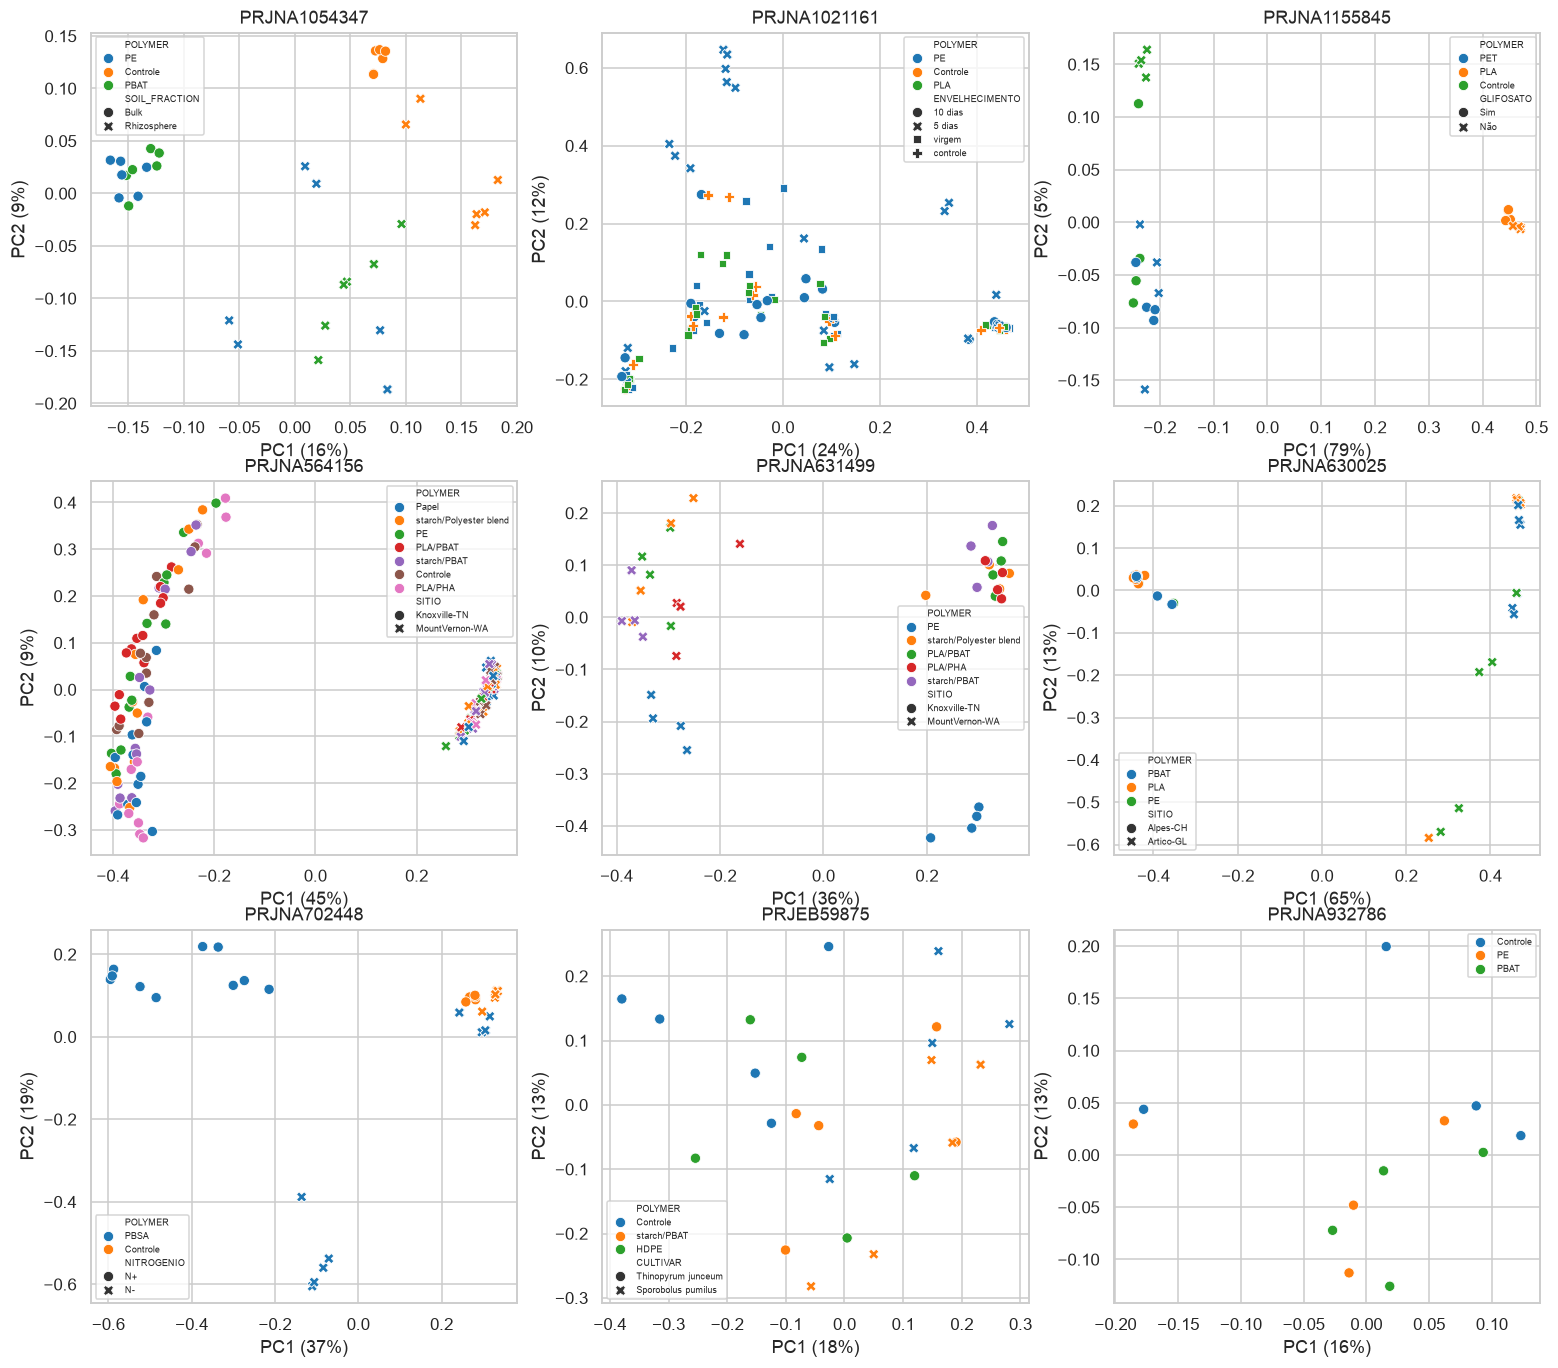

In [21]:
fig, axes = plt.subplots(3, 3, figsize=(17, 15))
for ax, (pj, (o, mm)) in zip(axes.flat, ords.items()):
    d = o.samples.iloc[:, :2].set_axis(['PC1','PC2'], axis=1).join(mm)
    style = desenhos[pj][0] if desenhos[pj][0] != 'POLYMER' else None
    if style == 'DIAS': style = 'ENVELHECIMENTO'
    sns.scatterplot(data=d, x='PC1', y='PC2', hue='POLYMER', style=style, ax=ax, s=45, palette='tab10')
    pe = o.proportion_explained.values[:2] * 100
    ax.set_title(pj); ax.set_xlabel(f'PC1 ({pe[0]:.0f}%)'); ax.set_ylabel(f'PC2 ({pe[1]:.0f}%)'); ax.legend(fontsize=6)
savefig('05_pcoa_por_projeto')

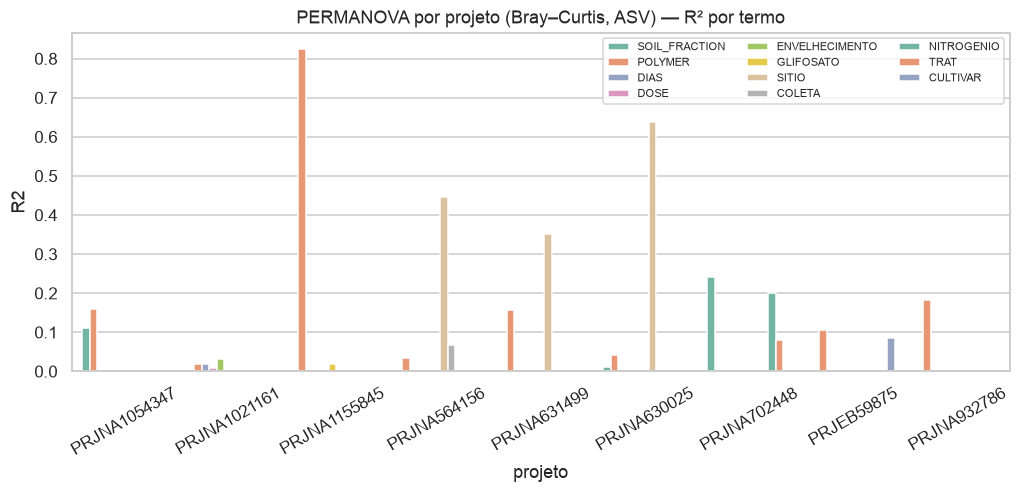

In [22]:
# resumo: R2 do polímero/tratamento vs outros fatores (Bray–Curtis)
bc = PP[PP.metrica == 'braycurtis'].copy()
bc['fator'] = np.where(bc.termo.isin(['POLYMER','TRAT']), 'Plástico', 'Outros fatores do desenho')
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=bc, x='projeto', y='R2', hue='termo', ax=ax, palette='Set2')
for i, (pj, d) in enumerate(bc.groupby('projeto', sort=False)): pass
ax.tick_params(axis='x', rotation=30); ax.set_title('PERMANOVA por projeto (Bray–Curtis, ASV) — R² por termo'); ax.legend(fontsize=7, ncol=3)
savefig('05_permanova_R2')

## 6. Abundância diferencial de gêneros

Dentro de cada estrato (projeto × fração): agregação em gênero, filtro de prevalência (≥ 20 % das amostras do projeto), transformação **CLR**
(pseudo‑contagem 0,5); diferença média de CLR (≈ log‑fold‑change) entre plástico e controle, erro‑padrão de Welch e
teste de Mann‑Whitney. Entre projetos: **meta‑análise de efeitos aleatórios** das diferenças + FDR (BH).

In [23]:
gcounts = counts.groupby(tax.LABEL).sum()
gcounts = gcounts.drop(index=[i for i in gcounts.index if i == 'Não classificado'])
tax_g = tax.drop_duplicates('LABEL').set_index('LABEL')[['Phylum','Class','Order','Family']]

def clr(df):
    L = np.log(df + 0.5); return L - L.mean(0)

def da_projeto(pj, grupo_a, grupo_b, col='CLASSE', subset=None, prev=0.2, por='BIOPROJECT'):
    s = meta.index[meta[por] == pj] if pj else meta.index
    if subset is not None: s = s[subset(meta.loc[s])]
    mm = meta.loc[s]; X = gcounts[s]; X = X.loc[(X > 0).mean(1) >= prev]
    C = clr(X); a = mm[col].isin(grupo_a).values; b = mm[col].isin(grupo_b).values
    if a.sum() < 3 or b.sum() < 3: return None
    Ca, Cb = C.loc[:, a], C.loc[:, b]
    diff = Ca.mean(1) - Cb.mean(1); se = np.sqrt(Ca.var(1) / a.sum() + Cb.var(1) / b.sum())
    p = [stats.mannwhitneyu(Ca.loc[g], Cb.loc[g]).pvalue for g in C.index]
    return pd.DataFrame({'projeto': pj, 'diff': diff, 'se': se, 'p': p, 'n_a': a.sum(), 'n_b': b.sum()})

def meta_da(per):
    rows = []
    for g, d in per.groupby(level=0):
        d = d[d.se > 0]
        if len(d) < 3: continue
        mu, se, p, tau2, I2 = dersimonian_laird(d['diff'], d.se ** 2)
        rows.append(dict(genero=g, k=len(d), log_fc=mu, se=se, p=p, I2=I2,
                         consist=(np.sign(d['diff']) == np.sign(mu)).mean(), n_sig_proj=(d.q < .05).sum()))
    r = pd.DataFrame(rows).set_index('genero'); r['q'] = multipletests(r.p, method='fdr_bh')[1]
    return r.join(tax_g).sort_values('p')

comparacoes = {'Plástico vs Controle': (['Biodegradável','Não biodegradável'], ['Controle']),
               'Biodegradável vs Controle': (['Biodegradável'], ['Controle']),
               'Não biodegradável vs Controle': (['Não biodegradável'], ['Controle'])}
DA, PER = {}, {}
for nome, (ga, gb) in comparacoes.items():
    per = [da_projeto(e, ga, gb, por='ESTRATO') for e in meta.ESTRATO.unique()]
    per = pd.concat([x for x in per if x is not None])
    per['q'] = per.groupby('projeto').p.transform(lambda p: multipletests(p, method='fdr_bh')[1])
    PER[nome] = per; DA[nome] = meta_da(per)
    DA[nome].round(4).to_csv(TAB / f"06_DA_{nome.replace(' ', '_')}.csv")
    print(f"{nome}: {per.projeto.nunique()} estratos projeto×fração | gêneros testados={len(DA[nome])} | q<0.05: {(DA[nome].q < .05).sum()}")
display(DA['Plástico vs Controle'].query('q < 0.05').head(30).round(3))

Plástico vs Controle: 8 estratos projeto×fração | gêneros testados=538 | q<0.05: 11


Biodegradável vs Controle: 8 estratos projeto×fração | gêneros testados=538 | q<0.05: 6


Não biodegradável vs Controle: 7 estratos projeto×fração | gêneros testados=528 | q<0.05: 11


,k,log_fc,se,p,I2,consist,n_sig_proj,q,Phylum,Class,Order,Family
genero,,,,,,,,,,,,
Ellin6055,7,-0.386,0.049,0.000,0.000,1.000,1,0.000,Proteobacteria,Alphaproteobacteria,Sphingomonadales,Sphingomonadaceae
AKYG587,7,-0.317,0.055,0.000,0.000,0.857,1,0.000,Planctomycetota,Phycisphaerae,Phycisphaerales,Phycisphaeraceae
FFCH7168,5,-0.523,0.114,0.000,0.000,0.800,0,0.001,Chloroflexi,Chloroflexia,Chloroflexales,Chloroflexaceae
Janthinobacterium,3,0.376,0.090,0.000,0.003,0.333,1,0.003,Proteobacteria,Gammaproteobacteria,Burkholderiales,Oxalobacteraceae
Skermanella,7,-0.367,0.088,0.000,0.000,1.000,0,0.003,Proteobacteria,Alphaproteobacteria,Azospirillales,Azospirillaceae
27F-1492R,4,0.617,0.159,0.000,0.000,1.000,1,0.010,Myxococcota,Myxococcia,Myxococcales,27F-1492R
Solirubrobacter,8,-0.143,0.038,0.000,0.000,0.750,1,0.011,Actinobacteriota,Thermoleophilia,Solirubrobacterales,Solirubrobacteraceae
Obscuribacteraceae,5,0.521,0.145,0.000,0.000,1.000,0,0.021,Cyanobacteria,Vampirivibrionia,Obscuribacterales,Obscuribacteraceae
Subgroup_25,8,-0.253,0.072,0.000,0.000,1.000,1,0.024,Acidobacteriota,Subgroup_25,Subgroup_25,Subgroup_25


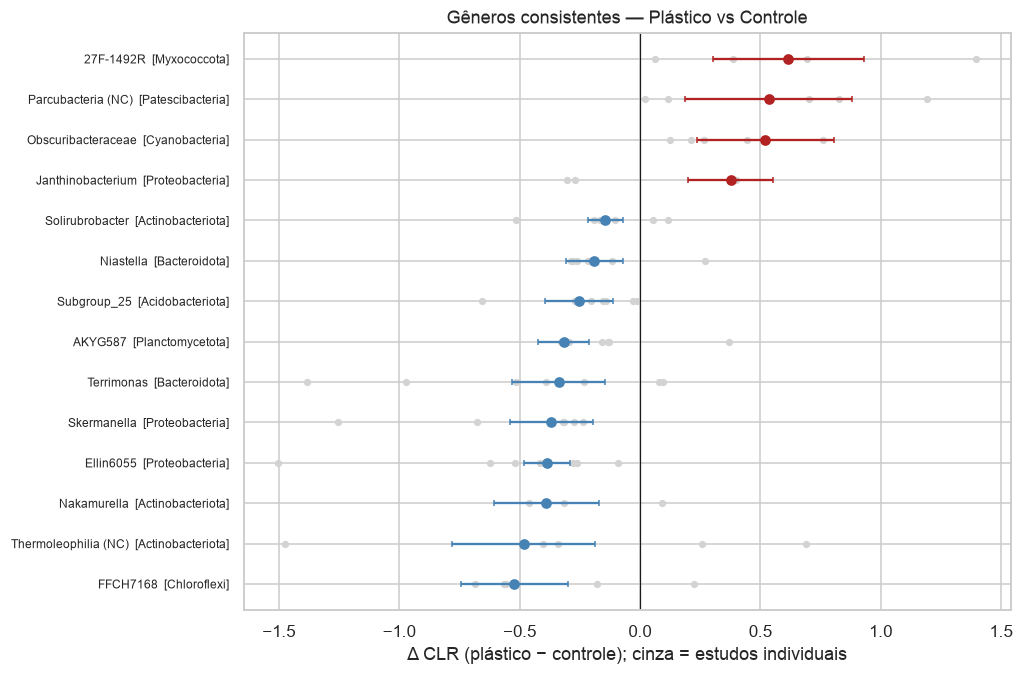

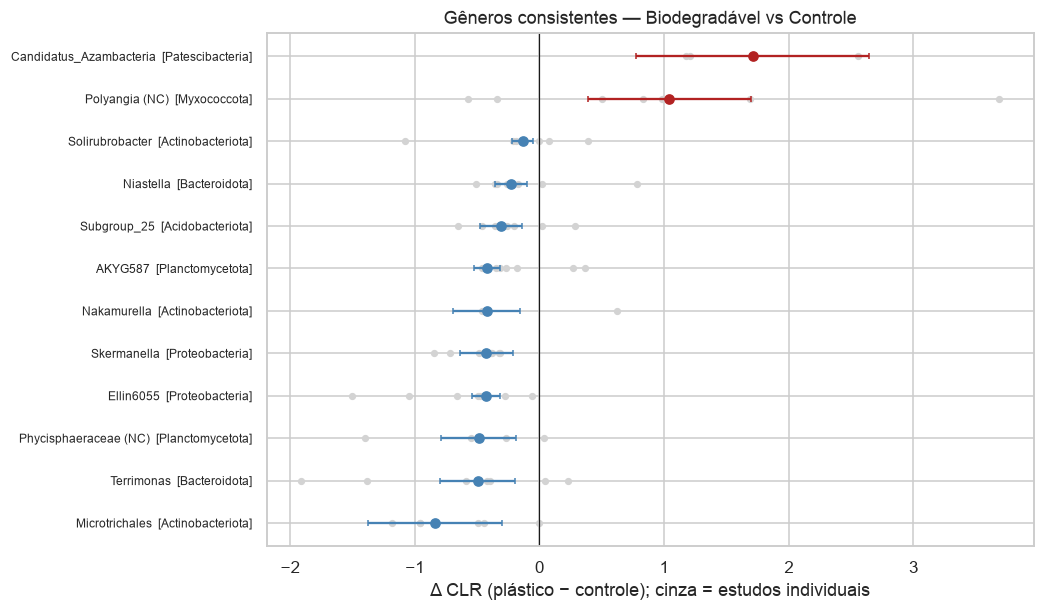

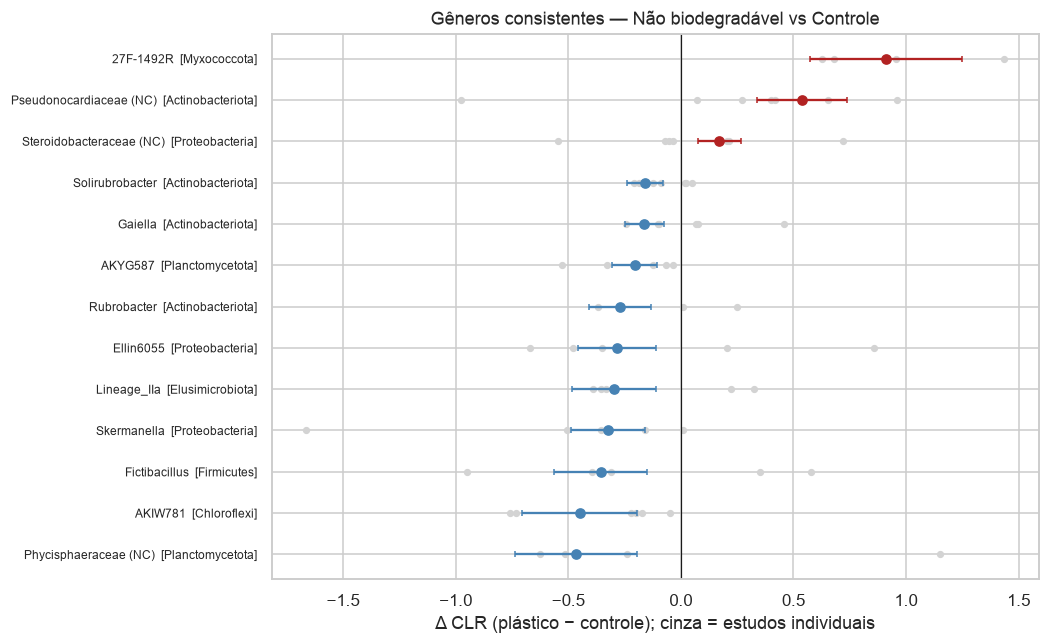

In [24]:
def forest_da(r, per, title, name, n=20):
    top = pd.concat([r.query('q < 0.1 and log_fc > 0').head(n // 2), r.query('q < 0.1 and log_fc < 0').head(n // 2)])
    if top.empty: top = r.head(n)
    top = top.sort_values('log_fc')
    fig, ax = plt.subplots(figsize=(9, .38 * len(top) + 1.5))
    for i, g in enumerate(top.index):
        d = per.loc[[g]]
        ax.scatter(d['diff'], [i] * len(d), c='lightgrey', s=14, zorder=1)
        ax.errorbar(top.at[g, 'log_fc'], i, xerr=1.96 * top.at[g, 'se'], fmt='o',
                    c='firebrick' if top.at[g, 'log_fc'] > 0 else 'steelblue', capsize=2, zorder=2)
    ax.set_yticks(range(len(top)), [f"{g}  [{top.at[g, 'Phylum']}]" for g in top.index], fontsize=8)
    ax.axvline(0, c='k', lw=.8); ax.set_xlabel('Δ CLR (plástico − controle); cinza = estudos individuais'); ax.set_title(title)
    savefig(name)

for nome in comparacoes:
    forest_da(DA[nome], PER[nome], f'Gêneros consistentes — {nome}', f"06_DA_{nome.split()[0].lower()}")

### 6.1 Gêneros enriquecidos na plastisfera

In [25]:
# (a) PRJNA630025: plastisfera vs bulk com mesmos polímeros; (b) EUA 2016-09: PRJNA631499 (PL) vs PRJNA564156 (BF), mesmos polímeros
res = []
r1 = da_projeto('PRJNA630025', ['Plastosphere'], ['Bulk'], col='SOIL_FRACTION'); r1['desenho'] = 'PRJNA630025'
r2 = da_projeto(None, ['Plastosphere'], ['Bulk'], col='SOIL_FRACTION',
                subset=lambda d: d.COLETA.eq('2016-09') & d.TRAT.eq('Plástico')); r2['desenho'] = 'EUA 2016-09 (631499 vs 564156)'
r3 = da_projeto('PRJNA702448', ['Plastosphere'], ['Bulk'], col='SOIL_FRACTION'); r3['desenho'] = 'PRJNA702448'
PL = pd.concat([r1, r2, r3]); PL['q'] = PL.groupby('desenho').p.transform(lambda p: multipletests(p, method='fdr_bh')[1])
wide = PL.pivot_table(index=PL.index, columns='desenho', values='diff')
qs = PL.pivot_table(index=PL.index, columns='desenho', values='q')
sig_up = ((wide > 1) & (qs < .05)).sum(1); sig_dn = ((wide < -1) & (qs < .05)).sum(1)
enr = wide[(sig_up >= 2) & (sig_dn == 0)].mean(1).sort_values(ascending=False)
dep = wide[(sig_dn >= 2) & (sig_up == 0)].mean(1).sort_values()
plast = pd.concat([enr.rename('ΔCLR médio').to_frame().assign(direcao='enriquecido na plastisfera'),
                   dep.rename('ΔCLR médio').to_frame().assign(direcao='depletado na plastisfera')]).join(tax_g[['Phylum','Family']])
plast.round(2).to_csv(TAB / '06_plastisfera_generos_consistentes.csv')
plast['n_desenhos_sig'] = np.where(plast.direcao.str.startswith('enr'), sig_up.reindex(plast.index), sig_dn.reindex(plast.index))
print(f'Enriquecidos (ΔCLR>1, q<0.05) em ≥2 de 3 desenhos: {len(enr)} | depletados: {len(dep)}')
for dsg in wide.columns:
    d = PL[PL.desenho == dsg]; print(f'\n{dsg}: {(d.q < .05).sum()} gêneros q<0.05 de {len(d)}')
    print('  ↑', ', '.join(d[d.q < .05].sort_values('diff', ascending=False).head(12).index))
    print('  ↓', ', '.join(d[d.q < .05].sort_values('diff').head(8).index))
display(plast.groupby('direcao').head(20).round(2))

Enriquecidos (ΔCLR>1, q<0.05) em ≥2 de 3 desenhos: 18 | depletados: 57

EUA 2016-09 (631499 vs 564156): 384 gêneros q<0.05 de 512
  ↑ Methylobacterium-Methylorubrum, Microbacterium, Williamsia, Hymenobacter, Deinococcus, Agrococcus, Beutenbergiaceae (NC), Rhodobacteraceae (NC), Rathayibacter, Patulibacter, Rhodococcus, Devosia
  ↓ Latescibacterota, Rokubacteriales, 11-24, Candidatus_Udaeobacter, Vicinamibacteraceae, Subgroup_17, MND1, WX65

PRJNA630025: 0 gêneros q<0.05 de 255
  ↑ 
  ↓ 

PRJNA702448: 151 gêneros q<0.05 de 308
  ↑ Stenotrophomonas, Alcaligenaceae (NC), Luteibacter, Allorhizobium-Neorhizobium-Pararhizobium-Rhizobium, Halomonas, Chitinophaga, Pseudoalteromonas, Microbacteriaceae (NC), Pseudomonas, Cupriavidus, Bosea, Enterobacteriaceae (NC)
  ↓ Rokubacteriales, MB-A2-108, SC-I-84, MND1, Gaiella, Rhizobiales (NC), RB41, Candidatus_Udaeobacter


,ΔCLR médio,direcao,Phylum,Family,n_desenhos_sig
LABEL,,,,,
Stenotrophomonas,5.71,enriquecido na plastisfera,Proteobacteria,Xanthomonadaceae,2
Williamsia,4.78,enriquecido na plastisfera,Actinobacteriota,Nocardiaceae,2
Alcaligenaceae (NC),4.46,enriquecido na plastisfera,Proteobacteria,Alcaligenaceae,2
Bosea,4.29,enriquecido na plastisfera,Proteobacteria,Beijerinckiaceae,2
Chryseobacterium,3.96,enriquecido na plastisfera,Bacteroidota,Weeksellaceae,2
Microbacteriaceae (NC),3.88,enriquecido na plastisfera,Actinobacteriota,Microbacteriaceae,2
Enterobacteriaceae (NC),3.82,enriquecido na plastisfera,Proteobacteria,Enterobacteriaceae,2
Neorhizobium,3.71,enriquecido na plastisfera,Proteobacteria,Rhizobiaceae,2
Rhodococcus,3.38,enriquecido na plastisfera,Actinobacteriota,Nocardiaceae,2


### 6.2 Gêneros descritos como degradadores de plástico
Lista de gêneros frequentemente citados na literatura como associados à degradação/colonização de plásticos.

In [26]:
degradadores = ['Pseudomonas','Bacillus','Rhodococcus','Streptomyces','Arthrobacter','Sphingomonas','Acinetobacter',
                'Comamonas','Variovorax','Acidovorax','Ramlibacter','Aquabacterium','Mycobacterium','Nocardia',
                'Pseudonocardia','Amycolatopsis','Paenibacillus','Stenotrophomonas','Microbacterium','Cupriavidus',
                'Burkholderia','Brevundimonas','Delftia','Leptothrix','Achromobacter','Chitinophaga','Flavobacterium',
                'Nocardioides','Lysobacter','Sphingobium','Novosphingobium','Streptomyces','Actinomadura','Thermobifida']
degradadores = [g for g in dict.fromkeys(degradadores) if g in gcounts.index]
tab_deg = pd.concat({k: v.reindex(degradadores)[['k','log_fc','q','consist']] for k, v in DA.items()}, axis=1)
tab_deg[('Plastisfera', 'ΔCLR_630025')] = wide.reindex(degradadores).get('PRJNA630025')
tab_deg[('Plastisfera', 'ΔCLR_EUA')] = wide.reindex(degradadores).get('EUA 2016-09 (631499 vs 564156)')
tab_deg.round(3).to_csv(TAB / '06_degradadores_conhecidos.csv'); tab_deg.round(2)

Plástico vs Controle                      Biodegradável vs Controle                      Não biodegradável vs Controle                      Plastisfera         
                                    k log_fc     q consist                         k log_fc     q consist                             k log_fc     q consist ΔCLR_630025 ΔCLR_EUA
genero                                                                                                                                                                           
Pseudomonas                       8.0   0.13  0.89    0.50                       8.0   0.23  0.89    0.50                           7.0   0.06  0.94    0.57        0.47     4.14
Bacillus                          6.0  -0.14  0.90    0.33                       6.0  -0.25  0.90    0.17                           6.0   0.13  0.88    0.50         NaN     4.66
Rhodococcus                       7.0   0.04  0.96    0.43                       7.0   0.04  0.97    0.43                           6.0   0.02  0.98    0.50        0.22     6.55
Streptomyces                      8.0   0.18  0.26    0.75                       8.0   0.35  0.52    0.75                           7.0   0.10  0.78    0.43       -0.02     0.16
Arthrobacter                      NaN    NaN   NaN     NaN                       NaN    NaN   NaN     NaN                           NaN    NaN   NaN     NaN         NaN     3.00
Sphingomonas                      8.0   0.03  0.92    0.62                       8.0   0.10  0.87    0.62                           7.0  -0.05  0.79    0.57        0.61     1.92
Acinetobacter                     5.0   0.10  0.94    0.20                       5.0   0.25  0.87    0.60                           5.0  -0.23  0.88    0.60         NaN     3.55
Variovorax                        NaN    NaN   NaN     NaN                       NaN    NaN   NaN     NaN                           NaN    NaN   NaN     NaN         NaN      NaN
Aquabacterium                     NaN    NaN   NaN     NaN                       NaN    NaN   NaN     NaN                           NaN    NaN   NaN     NaN         NaN      NaN
Mycobacterium                     8.0   0.07  0.91    0.50                       8.0   0.14  0.78    0.50                           7.0  -0.19  0.23    0.57        0.97     0.90
Nocardia                          8.0  -0.56  0.46    0.75                       8.0  -0.25  0.87    0.75                           7.0  -0.82  0.23    0.86        0.80    -0.45
Pseudonocardia                    8.0  -0.02  0.98    0.38                       8.0  -0.18  0.87    0.50                           7.0   0.09  0.88    0.71         NaN     0.70
Amycolatopsis                     4.0   0.30  0.66    0.50                       4.0   0.13  0.95    0.25                           4.0   0.45  0.62    0.75         NaN     1.87
Paenibacillus                     8.0  -0.32  0.48    0.62                       8.0  -0.41  0.54    0.50                           7.0  -0.10  0.88    0.57         NaN     1.05
Stenotrophomonas                  8.0  -0.01  0.99    0.50                       8.0  -0.18  0.86    0.62                           7.0  -0.03  0.98    0.43         NaN     4.53
Microbacterium                    4.0  -0.29  0.70    0.75                       4.0  -0.29  0.70    0.75                           4.0  -0.55  0.72    0.75         NaN     7.76
Cupriavidus                       6.0   0.65  0.47    0.83                       6.0   0.85  0.82    0.67                           6.0   0.33  0.40    0.67         NaN    -1.58
Brevundimonas                     8.0   0.41  0.46    0.75                       8.0   0.66  0.60    0.75                           7.0   0.11  0.35    0.71       -0.24     5.88
Chitinophaga                      7.0   0.12  0.93    0.43                       7.0   0.26  0.88    0.29                           7.0   0.16  0.88    0.57         NaN    -1.83
Flavobacterium                    8.0  -0.34  0.61    0.62                       8.0  -0.31  0.77    

## 7. Efeitos específicos de desenho

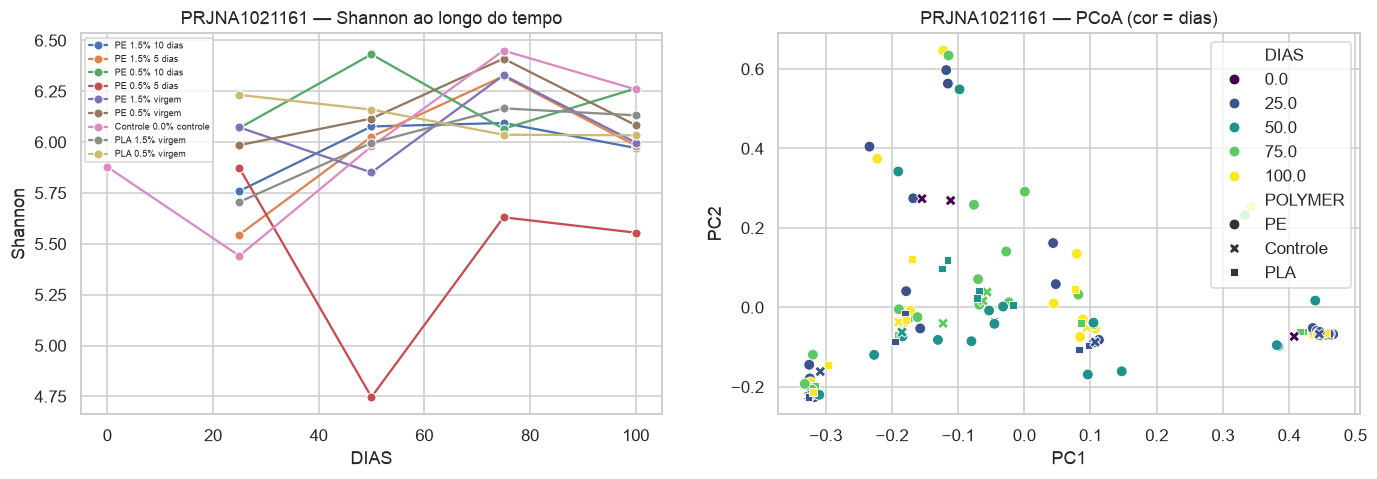

                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                    5.9845      0.158     37.847      0.000       5.670       6.299
C(DIAS)[T.50.0]              0.0201      0.135      0.149      0.882      -0.248       0.288
C(DIAS)[T.75.0]              0.2266      0.135      1.680      0.096      -0.041       0.495
C(DIAS)[T.100.0]             0.0970      0.135      0.719      0.474      -0.171       0.365
POLYMER[T.PLA]              -0.0479      0.135     -0.355      0.723      -0.316       0.220
ENVELHECIMENTO[T.5 dias]    -0.3811      0.135     -2.826      0.006      -0.649      -0.113
ENVELHECIMENTO[T.virgem]     0.0141      0.135      0.105      0.917      -0.254       0.282
DOSE                         0.0212      0.095      0.222      0.825      -0.168       0.211


In [27]:
# PRJNA1021161 — tempo × dose × envelhecimento
d = A[A.BIOPROJECT == 'PRJNA1021161'].copy()
d['grupo'] = d.POLYMER + ' ' + d.DOSE.astype(str) + '% ' + d.ENVELHECIMENTO
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.lineplot(data=d, x='DIAS', y='Shannon', hue='grupo', marker='o', ax=ax[0], errorbar=None); ax[0].legend(fontsize=6)
o, mm = ords['PRJNA1021161']; p = o.samples.iloc[:, :2].set_axis(['PC1','PC2'], axis=1).join(mm)
sns.scatterplot(data=p, x='PC1', y='PC2', hue='DIAS', style='POLYMER', palette='viridis', ax=ax[1], s=50)
ax[0].set_title('PRJNA1021161 — Shannon ao longo do tempo'); ax[1].set_title('PRJNA1021161 — PCoA (cor = dias)')
savefig('07_PRJNA1021161')
# só amostras com plástico (nos controles dose/envelhecimento não se aplicam → colinearidade)
dp = d[d.POLYMER.ne('Controle')]
print(smf.ols('Shannon ~ C(DIAS) + POLYMER + DOSE + ENVELHECIMENTO', dp).fit().summary().tables[1])

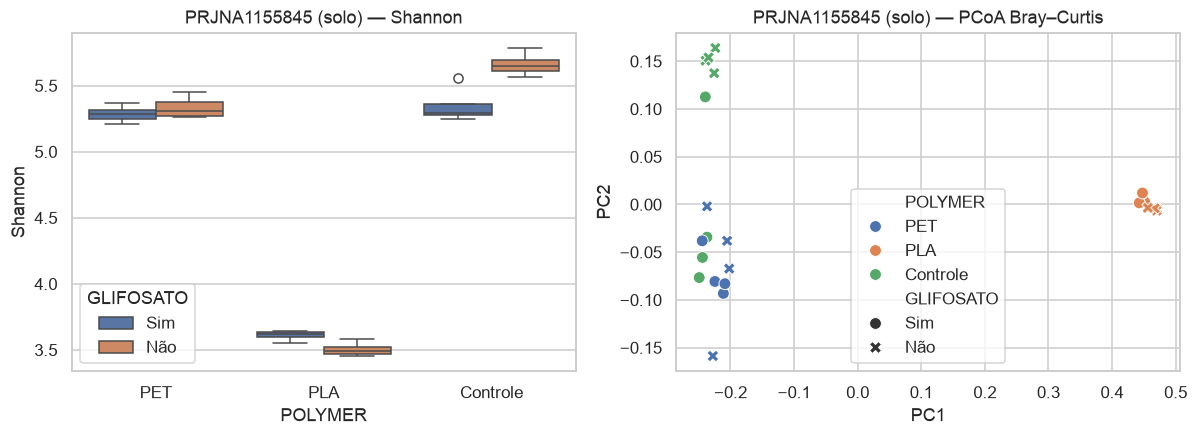

,gl,SS,R2,F,p
GLIFOSATO,1.0,0.0598,0.0188,2.7718,0.067
POLYMER,2.0,2.6179,0.8254,60.7199,0.001
PxG,2.0,0.1061,0.0334,2.4598,0.084
Residual,18.0,0.3880,0.1223,NaN,NaN


                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept                           5.6599      0.043    130.211      0.000       5.569       5.751
POLYMER[T.PET]                     -0.3271      0.061     -5.322      0.000      -0.456      -0.198
POLYMER[T.PLA]                     -2.1559      0.061    -35.072      0.000      -2.285      -2.027
GLIFOSATO[T.Sim]                   -0.3133      0.061     -5.096      0.000      -0.442      -0.184
POLYMER[T.PET]:GLIFOSATO[T.Sim]     0.2647      0.087      3.045      0.007       0.082       0.447
POLYMER[T.PLA]:GLIFOSATO[T.Sim]     0.4193      0.087      4.823      0.000       0.237       0.602


In [28]:
# PRJNA1155845 — microplástico × glifosato (somente SOLO; o intestino está no notebook de comparações)
d = A[A.BIOPROJECT == 'PRJNA1155845']
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=d, x='POLYMER', y='Shannon', hue='GLIFOSATO', ax=ax[0])
o, mm = ords['PRJNA1155845']; p = o.samples.iloc[:, :2].set_axis(['PC1','PC2'], axis=1).join(mm)
sns.scatterplot(data=p, x='PC1', y='PC2', hue='POLYMER', style='GLIFOSATO', ax=ax[1], s=60)
ax[0].set_title('PRJNA1155845 (solo) — Shannon'); ax[1].set_title('PRJNA1155845 (solo) — PCoA Bray–Curtis'); savefig('07_PRJNA1155845')
s = meta.index[meta.BIOPROJECT == 'PRJNA1155845']; X = rare[s]; X = X.loc[X.sum(1) > 0]
dm = beta_diversity('braycurtis', X.T.values, ids=list(s)); mm = meta.loc[s].copy(); mm['PxG'] = mm.POLYMER + ':' + mm.GLIFOSATO
display(permanova_seq(dm.data, mm, ['GLIFOSATO', 'POLYMER', 'PxG'], perms=999).round(4))
print(smf.ols('Shannon ~ POLYMER * GLIFOSATO', d).fit().summary().tables[1])

In [29]:
# PRJNA564156 — mesmo experimento em dois sítios e 4 coletas: o polímero pesa em algum sítio/época?
rows = []
for (cl, col), mm in meta[meta.BIOPROJECT == 'PRJNA564156'].groupby(['SITIO', 'COLETA']):
    if mm.POLYMER.nunique() < 2 or len(mm) < 8: continue
    X = rare[mm.index]; X = X.loc[X.sum(1) > 0]
    dm = beta_diversity('braycurtis', X.T.values, ids=list(mm.index))
    r = permanova_seq(dm.data, mm, ['POLYMER'], perms=999)
    rows.append(dict(sitio=cl, coleta=col, n=len(mm), R2_polimero=r.at['POLYMER', 'R2'], p=r.at['POLYMER', 'p']))
T564 = pd.DataFrame(rows); T564.round(3).to_csv(TAB / '07_PRJNA564156_por_clima_coleta.csv', index=False); T564.round(3)

,sitio,coleta,n,R2_polimero,p
0,Knoxville-TN,2015-05,21,0.264,0.793
1,Knoxville-TN,2015-09,21,0.310,0.344
2,Knoxville-TN,2016-05,21,0.270,0.720
3,Knoxville-TN,2016-09,21,0.322,0.281
4,MountVernon-WA,2015-05,21,0.285,0.814
5,MountVernon-WA,2015-09,21,0.364,0.012
6,MountVernon-WA,2016-05,21,0.289,0.739
7,MountVernon-WA,2016-09,21,0.349,0.007


## 8. Variáveis ambientais (exploratório)
Correlação (Spearman) entre os eixos da PCoA global (gênero) e variáveis de clima/solo. **Atenção:** como as variáveis
são quase constantes dentro de cada projeto, o *n* efetivo é o número de locais (~10), não o número de amostras.
Por isso também mostramos a correlação usando **centróides por projeto × local**.

In [30]:
env = ['pH','SOC(g/kg)','TN(g/kg)','C/N','AP(mg/kg)','AK(mg/kg)','ANNUAL_RAINFALL(mm)','AVG_ANNUAL_TEMPERATURE']
rows = []
cent = PC.groupby(['BIOPROJECT', 'CLIMATE'], dropna=False)[['PC1','PC2','PC3'] + env].mean()
for v in env:
    for ax_ in ['PC1','PC2','PC3']:
        d = PC[[v, ax_]].dropna(); c = cent[[v, ax_]].dropna()
        r_s = stats.spearmanr(d[v], d[ax_]) if d[v].nunique() > 2 else (np.nan, np.nan)
        r_c = stats.spearmanr(c[v], c[ax_]) if len(c) > 3 else (np.nan, np.nan)
        rows.append(dict(variavel=v, eixo=ax_, rho_amostras=r_s[0], rho_centroides=r_c[0], p_centroides=r_c[1], n_locais=len(c)))
ENV = pd.DataFrame(rows); ENV.round(3).to_csv(TAB / '08_ambiente_pcoa.csv', index=False)
ENV.pivot(index='variavel', columns='eixo', values=['rho_centroides','p_centroides']).round(2)

rho_centroides             p_centroides            
eixo                              PC1   PC2   PC3          PC1   PC2   PC3
variavel                                                                  
AK(mg/kg)                       -0.45 -0.11  0.89         0.45  0.86  0.04
ANNUAL_RAINFALL(mm)              0.00  0.00 -0.21         0.99  1.00  0.51
AP(mg/kg)                        0.33  0.58  0.58         0.52  0.23  0.23
AVG_ANNUAL_TEMPERATURE          -0.02  0.36  0.06         0.96  0.25  0.85
C/N                              0.39  0.00 -0.85         0.34  1.00  0.01
SOC(g/kg)                        0.47 -0.20 -0.74         0.17  0.57  0.01
TN(g/kg)                         0.30  0.15 -0.59         0.52  0.75  0.16
pH                              -0.23  0.24  0.64         0.52  0.51  0.04

## 9. Análises adicionais: t‑SNE, modelos lineares, heatmaps, ISA e db‑RDA

| Análise | Pergunta | Onde |
|---|---|---|
| **t‑SNE** (Bray–Curtis) | como as amostras se agrupam, visto de forma não linear | 9.1 |
| **Modelos lineares** | diversidade alfa com interações; gêneros que respondem ao tratamento (efeito fixo de estrato, estilo MaAsLin2) | 9.2 |
| **Heatmaps** | padrões de abundância dos gêneros‑chave; R² por projeto × fator | 9.3 |
| **ISA / IndVal** | quais gêneros são *indicadores* de cada compartimento/classe de plástico/polímero | 9.4 |
| **db‑RDA** (Bray–Curtis) | ordenação restrita: quanto da composição os fatores explicam e em que direção | 9.5 |

### 9.1 t‑SNE sobre Bray–Curtis
t‑SNE com distância pré‑computada (Bray–Curtis). Serve **só para visualização**: distâncias entre grupos distantes e
tamanhos de cluster não têm interpretação quantitativa. Testamos 3 perplexidades para verificar se os agrupamentos são estáveis.

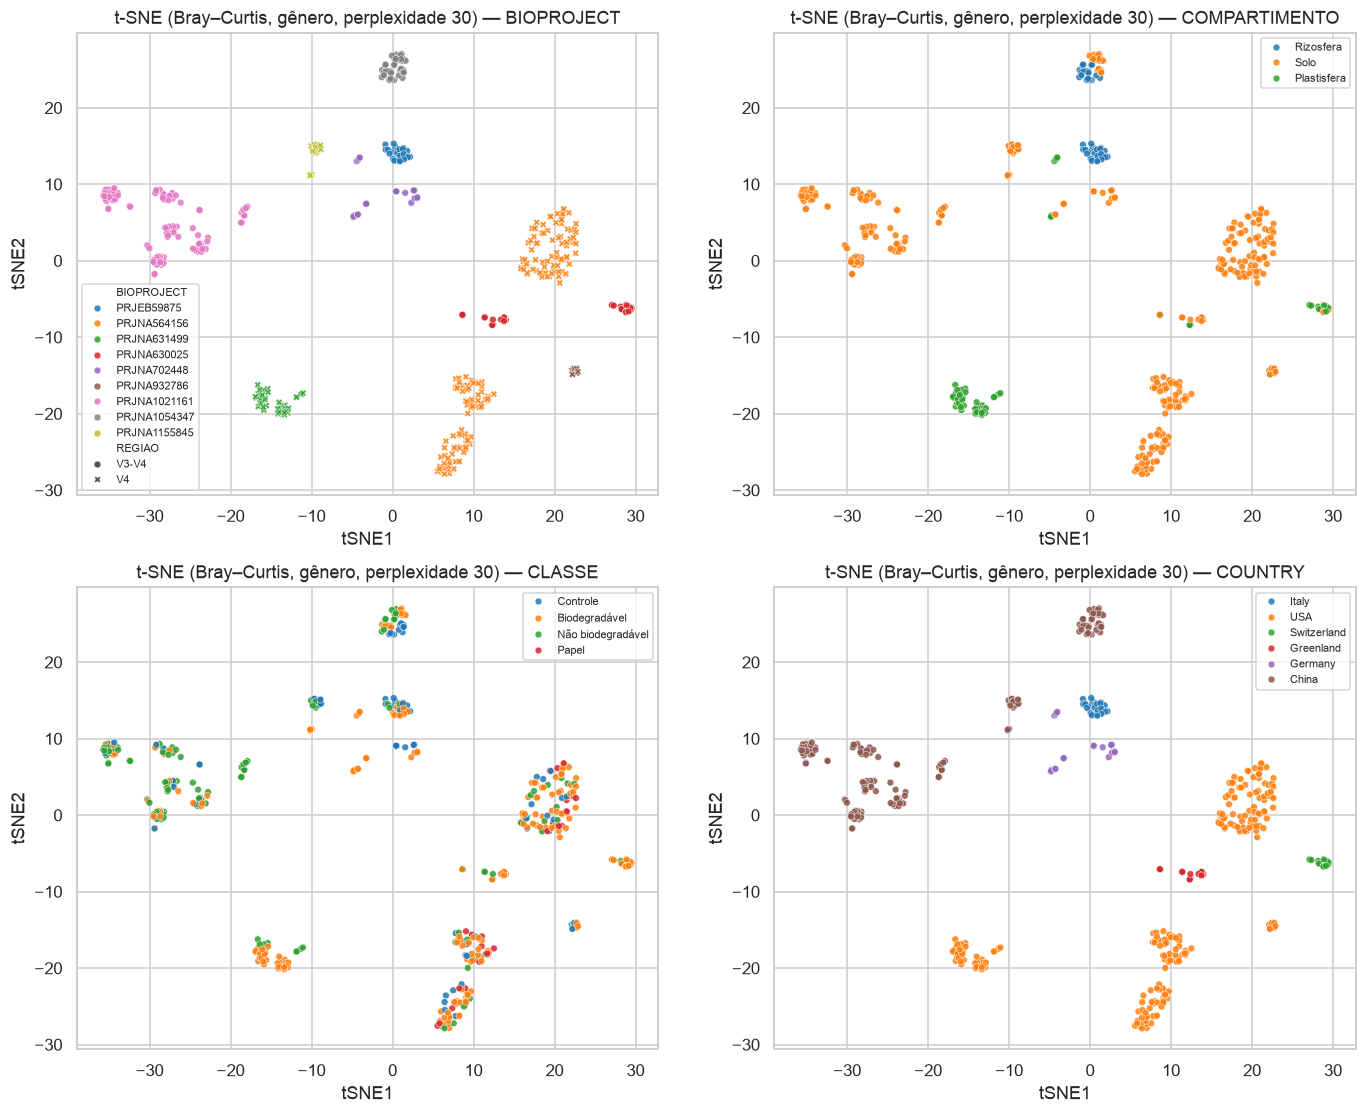

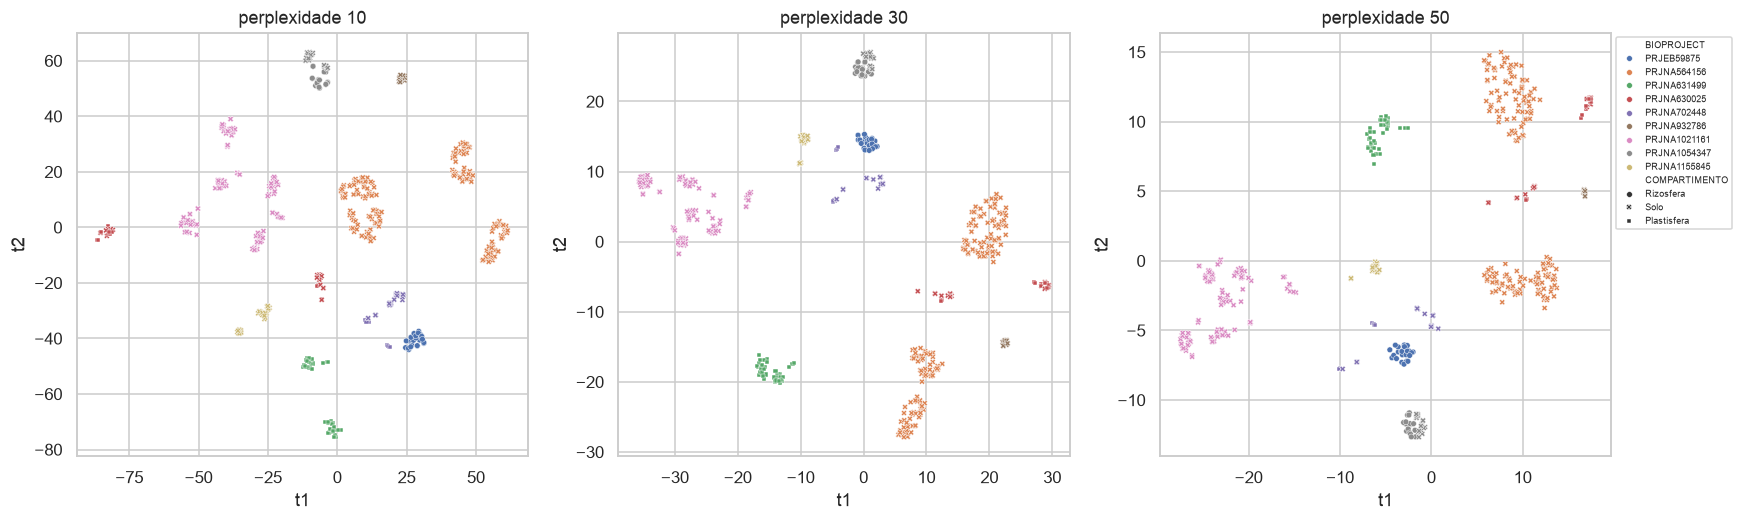

In [31]:
from sklearn.manifold import TSNE
def tsne(D, perplexity=30, seed=42):
    return TSNE(n_components=2, metric='precomputed', init='random', perplexity=perplexity,
                random_state=seed, max_iter=2000).fit_transform(np.asarray(D))

TS = pd.DataFrame(tsne(bc_gen.data), index=gen_rel.columns, columns=['tSNE1', 'tSNE2']).join(meta)
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, (hue, st) in zip(axes.flat, [('BIOPROJECT', 'REGIAO'), ('COMPARTIMENTO', None), ('CLASSE', None), ('COUNTRY', None)]):
    sns.scatterplot(data=TS, x='tSNE1', y='tSNE2', hue=hue, style=st, s=20, alpha=.85, ax=ax, palette='tab10')
    ax.set_title(f't-SNE (Bray–Curtis, gênero, perplexidade 30) — {hue}'); ax.legend(fontsize=7)
savefig('09_tsne_global')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, perp in zip(axes, [10, 30, 50]):
    e = pd.DataFrame(tsne(bc_gen.data, perp), index=gen_rel.columns, columns=['t1', 't2']).join(meta)
    sns.scatterplot(data=e, x='t1', y='t2', hue='BIOPROJECT', style='COMPARTIMENTO', s=14, ax=ax, legend=(perp == 50))
    ax.set_title(f'perplexidade {perp}')
axes[-1].legend(fontsize=6, bbox_to_anchor=(1, 1)); savefig('09_tsne_perplexidade')

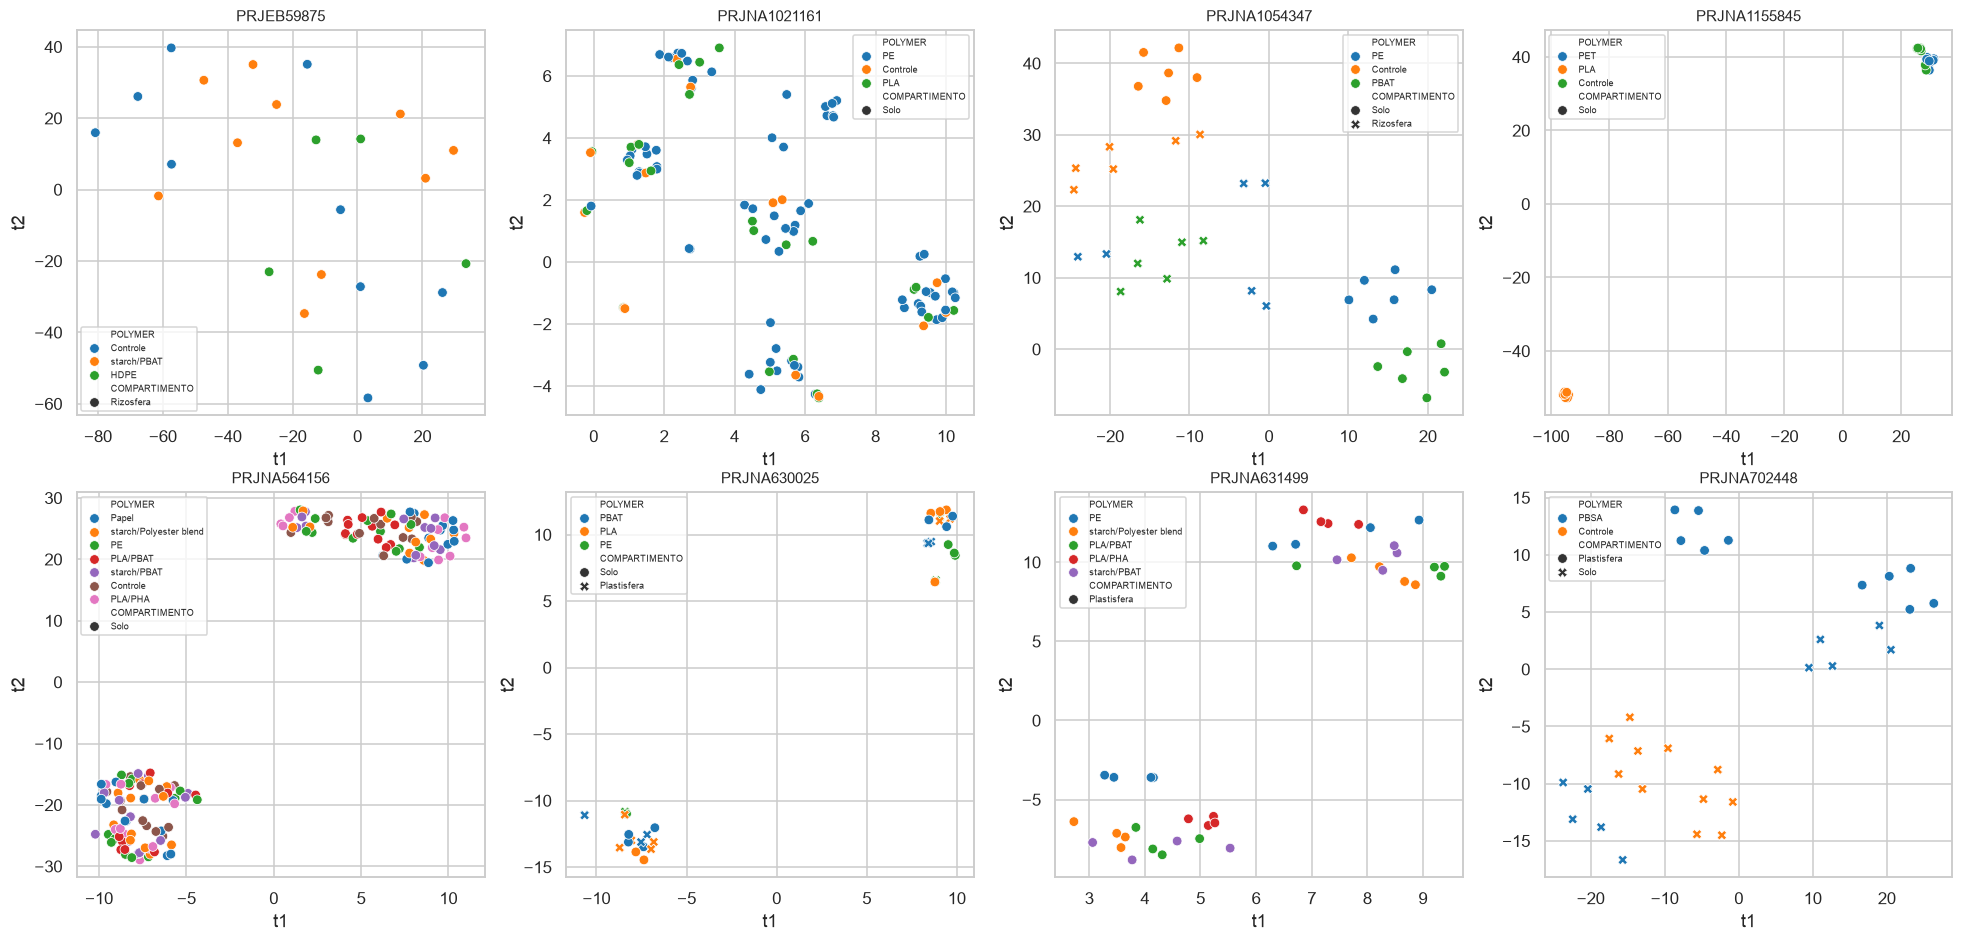

In [32]:
# t-SNE dentro dos desenhos com plástico e controle (ASV, rarefeito): o tratamento aparece quando o estudo é fixado?
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, (pj, mm) in zip(axes.flat, [(p, d) for p, d in meta.groupby('BIOPROJECT') if len(d) >= 12]):
    s = list(mm.index); X = rare[s]; X = X.loc[X.sum(1) > 0]
    D = beta_diversity('braycurtis', X.T.values, ids=s).data
    e = pd.DataFrame(tsne(D, perplexity=min(30, (len(s) - 1) // 3)), index=s, columns=['t1', 't2']).join(meta)
    sns.scatterplot(data=e, x='t1', y='t2', hue='POLYMER', style='COMPARTIMENTO', s=40, ax=ax, palette='tab10')
    ax.set_title(pj, fontsize=10); ax.legend(fontsize=6)
savefig('09_tsne_por_projeto')

### 9.2 Modelos lineares

**(a) Diversidade alfa.** Dois modelos, nos estratos que têm controle (sem papel):
* **ANOVA tipo II** com projeto como efeito fixo: `métrica ~ projeto + CLASSE × fração`
* **Modelo misto** com interação: `métrica ~ CLASSE × fração + (1 | projeto)`

**(b) Gêneros (estilo MaAsLin2).** Para cada gênero (prevalência ≥ 25 %): `CLR ~ CLASSE + estrato` (estrato = projeto × fração como
efeito fixo, ou seja, compara plástico e controle **dentro** de cada estrato). Coeficientes vs. controle, FDR (BH).

ANOVA tipo II (projeto como efeito fixo):


Riqueza           Shannon           FaithPD           Pielou        
                             F  PR(>F)         F  PR(>F)         F  PR(>F)        F  PR(>F)
C(BIOPROJECT)         190.1804  0.0000  110.9439  0.0000  136.7024  0.0000  54.9862  0.0000
CLASSE                  2.1454  0.1185    8.1487  0.0003    1.6829  0.1873   6.4854  0.0017
SOIL_FRACTION           1.1775  0.2786    0.5761  0.4483    1.0393  0.3087   0.2754  0.6000
CLASSE:SOIL_FRACTION    2.2608  0.1057    3.1948  0.0421    2.5232  0.0816   2.0942  0.1247
Residual                   NaN     NaN       NaN     NaN       NaN     NaN      NaN     NaN

Modelo misto (coeficientes em desvios-padrão, referência = Controle na fração Bulk):


,metrica,termo,coef_DP,IC95_inf,IC95_sup,p
0,Riqueza,CLASSE[T.Biodegradável],-0.199,-0.344,-0.054,0.007
1,Riqueza,CLASSE[T.Não biodegradável],-0.159,-0.317,-0.001,0.049
2,Riqueza,CLASSE[T.Biodegradável]:SOIL_FRACTION[T.Rhizos...,0.396,0.028,0.764,0.035
3,Riqueza,CLASSE[T.Não biodegradável]:SOIL_FRACTION[T.Rh...,0.247,-0.163,0.657,0.238
4,Shannon,CLASSE[T.Biodegradável],-0.415,-0.589,-0.240,0.000
5,Shannon,CLASSE[T.Não biodegradável],-0.226,-0.416,-0.035,0.020
6,Shannon,CLASSE[T.Biodegradável]:SOIL_FRACTION[T.Rhizos...,0.570,0.126,1.013,0.012
7,Shannon,CLASSE[T.Não biodegradável]:SOIL_FRACTION[T.Rh...,0.317,-0.176,0.811,0.208
8,FaithPD,CLASSE[T.Biodegradável],-0.212,-0.377,-0.046,0.012
9,FaithPD,CLASSE[T.Não biodegradável],-0.170,-0.351,0.011,0.065


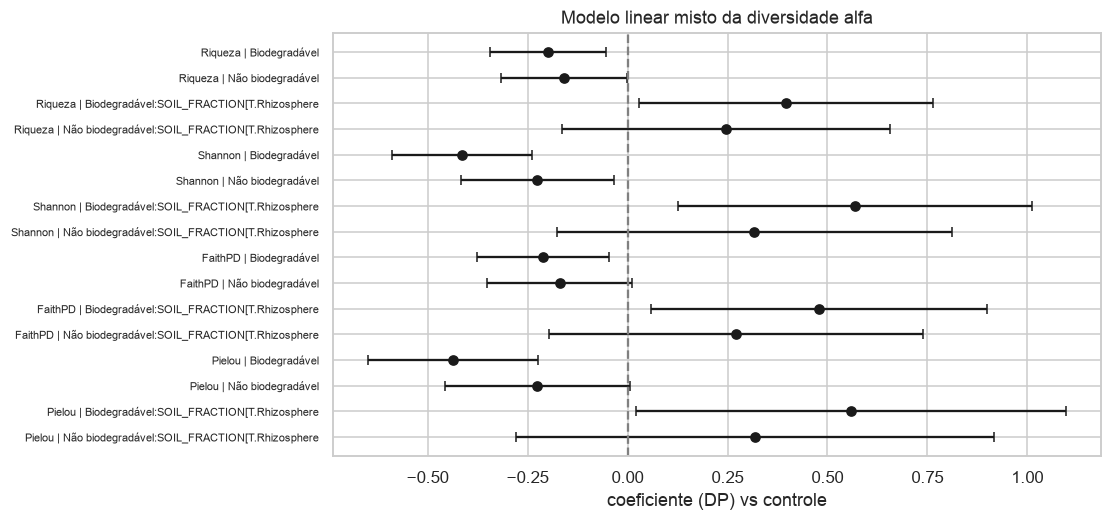

In [33]:
from statsmodels.stats.anova import anova_lm
sub = A[A.ESTRATO.isin(ef.projeto.unique()) & A.CLASSE.ne('Papel')].copy()
sub['CLASSE'] = pd.Categorical(sub.CLASSE, ['Controle', 'Biodegradável', 'Não biodegradável'])
rows, anovas = [], {}
for mt in ['Riqueza', 'Shannon', 'FaithPD', 'Pielou']:
    sub['y'] = (sub[mt] - sub[mt].mean()) / sub[mt].std()
    ols = smf.ols('y ~ C(BIOPROJECT) + CLASSE * SOIL_FRACTION', sub).fit()
    anovas[mt] = anova_lm(ols, typ=2)
    lmm = smf.mixedlm('y ~ CLASSE * SOIL_FRACTION', sub, groups=sub.BIOPROJECT).fit(reml=True)
    for t in lmm.params.index:
        if t.startswith('CLASSE'):
            rows.append(dict(metrica=mt, termo=t, coef_DP=lmm.params[t], IC95_inf=lmm.conf_int().loc[t, 0],
                             IC95_sup=lmm.conf_int().loc[t, 1], p=lmm.pvalues[t]))
LM_alfa = pd.DataFrame(rows); LM_alfa.round(4).to_csv(TAB / '09_lm_alfa_misto.csv', index=False)
AN = pd.concat({k: v[['F', 'PR(>F)']] for k, v in anovas.items()}, axis=1); AN.round(4).to_csv(TAB / '09_lm_alfa_anova.csv')
print('ANOVA tipo II (projeto como efeito fixo):'); display(AN.round(4))
print('Modelo misto (coeficientes em desvios-padrão, referência = Controle na fração Bulk):'); display(LM_alfa.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
d = LM_alfa.copy(); d['lbl'] = d.metrica + ' | ' + d.termo.str.replace('CLASSE[T.', '', regex=False).str.replace(']', '', regex=False)
d = d.iloc[::-1].reset_index(drop=True)
ax.errorbar(d.coef_DP, d.index, xerr=[d.coef_DP - d.IC95_inf, d.IC95_sup - d.coef_DP], fmt='o', c='k', capsize=3)
ax.set_yticks(d.index, d.lbl, fontsize=7); ax.axvline(0, ls='--', c='grey'); ax.set_xlabel('coeficiente (DP) vs controle')
ax.set_title('Modelo linear misto da diversidade alfa'); savefig('09_lm_alfa_coef')

Biodegradável vs Controle: 10 de 530 gêneros com q < 0.05 (↑ 3 / ↓ 7)
Não biodegradável vs Controle: 0 de 530 gêneros com q < 0.05 (↑ 0 / ↓ 0)


,nivel,coef,EP,t,p,q,Phylum,Family
LABEL,,,,,,,,
Adhaeribacter,Biodegradável,-0.749,0.205,-3.661,0.000,0.022,Bacteroidota,Hymenobacteraceae
Terrimonas,Biodegradável,-0.636,0.171,-3.710,0.000,0.022,Bacteroidota,Chitinophagaceae
Paenibacillus,Biodegradável,-0.616,0.164,-3.751,0.000,0.022,Firmicutes,Paenibacillaceae
S085,Biodegradável,-0.605,0.157,-3.852,0.000,0.022,Chloroflexi,S085
JG30-KF-CM66,Biodegradável,-0.597,0.151,-3.960,0.000,0.022,Chloroflexi,JG30-KF-CM66
Micrococcaceae (NC),Biodegradável,-0.408,0.110,-3.708,0.000,0.022,Actinobacteriota,Micrococcaceae
RB41,Biodegradável,-0.345,0.093,-3.702,0.000,0.022,Acidobacteriota,Pyrinomonadaceae
Escherichia-Shigella,Biodegradável,0.189,0.053,3.556,0.000,0.025,Proteobacteria,Enterobacteriaceae
Cutibacterium,Biodegradável,0.527,0.147,3.594,0.000,0.025,Actinobacteriota,Propionibacteriaceae


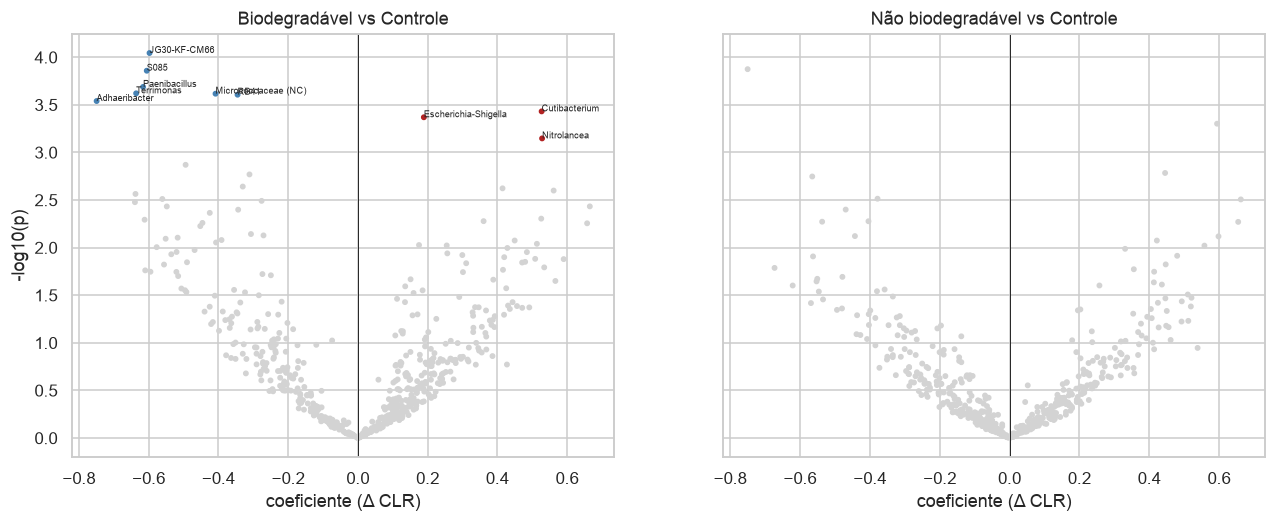

In [34]:
def lm_generos(samples, termo='CLASSE', ref='Controle', bloco='ESTRATO', prev=0.25):
    '''OLS vetorizado para todos os gêneros: CLR ~ termo + bloco (efeito fixo). Retorna coef, EP, p, q por nível.'''
    mm = meta.loc[samples]; X = gcounts[samples]; X = X.loc[(X > 0).mean(1) >= prev]
    Y = clr(X).T.values                                                     # amostras × gêneros
    lv = [l for l in mm[termo].unique() if l != ref]
    Xd = np.column_stack([np.ones(len(mm))] + [(mm[termo] == l).values.astype(float) for l in lv] +
                         [pd.get_dummies(mm[bloco], drop_first=True).values.astype(float)])
    XtX_inv = np.linalg.pinv(Xd.T @ Xd); B = XtX_inv @ Xd.T @ Y
    res = Y - Xd @ B; dfr = len(mm) - np.linalg.matrix_rank(Xd); s2 = (res ** 2).sum(0) / dfr
    out = []
    for i, l in enumerate(lv, start=1):
        se = np.sqrt(XtX_inv[i, i] * s2); t = B[i] / se; p = 2 * stats.t.sf(np.abs(t), dfr)
        out.append(pd.DataFrame({'nivel': l, 'coef': B[i], 'EP': se, 't': t, 'p': p}, index=X.index))
    out = pd.concat(out); out['q'] = out.groupby('nivel').p.transform(lambda p: multipletests(p, method='fdr_bh')[1])
    return out.join(tax_g[['Phylum', 'Family']])

s_ctrl = list(sub.index)
LMG = lm_generos(s_ctrl); LMG.round(4).to_csv(TAB / '09_lm_generos.csv')
for nv, d in LMG.groupby('nivel'):
    print(f'{nv} vs Controle: {(d.q < .05).sum()} de {len(d)} gêneros com q < 0.05 (↑ {((d.q < .05) & (d.coef > 0)).sum()} / ↓ {((d.q < .05) & (d.coef < 0)).sum()})')
display(LMG[LMG.q < .05].sort_values('coef').round(3).groupby('nivel').head(12))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (nv, d) in zip(axes, LMG.groupby('nivel')):
    sig = d.q < .05
    ax.scatter(d.coef, -np.log10(d.p), s=8, c=np.where(sig, np.where(d.coef > 0, 'firebrick', 'steelblue'), 'lightgrey'))
    for g, r in d[sig].sort_values('p').head(10).iterrows(): ax.annotate(g, (r.coef, -np.log10(r.p)), fontsize=6)
    ax.axvline(0, c='k', lw=.6); ax.set_title(f'{nv} vs Controle'); ax.set_xlabel('coeficiente (Δ CLR)')
axes[0].set_ylabel('-log10(p)'); savefig('09_lm_generos_volcano')

### 9.3 Heatmaps

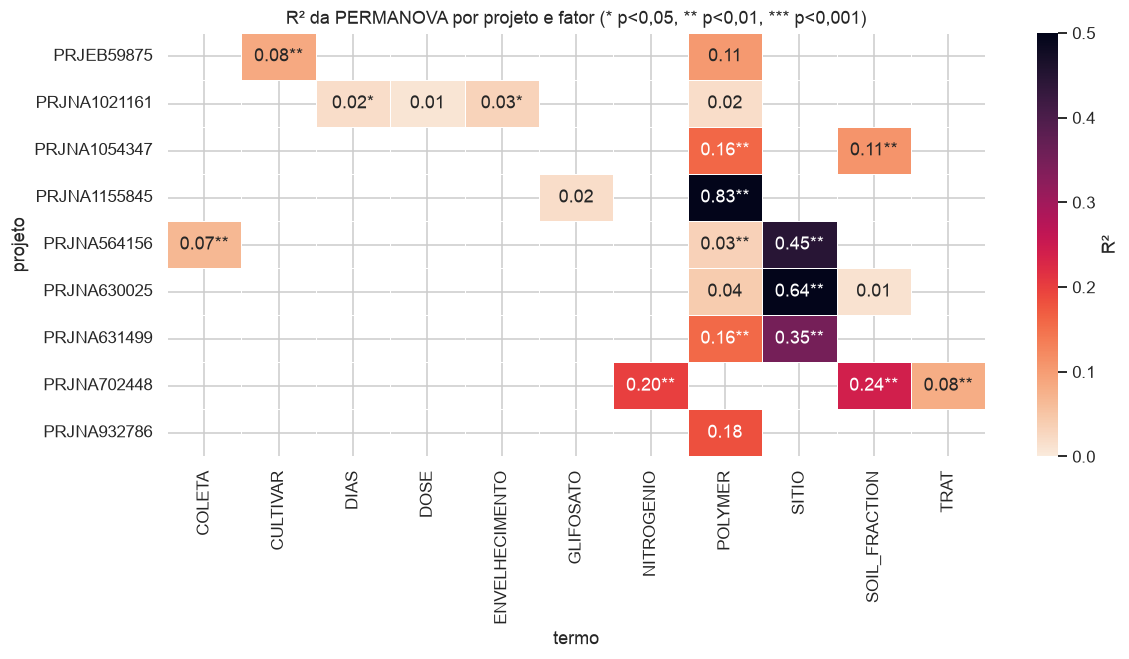

In [35]:
# (a) R² da PERMANOVA por projeto × fator (Bray–Curtis, ASV)
H = PP[PP.metrica == 'braycurtis'].pivot_table(index='projeto', columns='termo', values='R2')
Hp = PP[PP.metrica == 'braycurtis'].pivot_table(index='projeto', columns='termo', values='p')
annot = H.map(lambda v: '' if pd.isna(v) else f'{v:.2f}') + Hp.map(lambda p: '' if pd.isna(p) else ('***' if p < .001 else '**' if p < .01 else '*' if p < .05 else ''))
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(H, annot=annot, fmt='', cmap='rocket_r', vmin=0, vmax=.5, ax=ax, cbar_kws={'label': 'R²'}, linewidths=.5, linecolor='white')
ax.set_title('R² da PERMANOVA por projeto e fator (* p<0,05, ** p<0,01, *** p<0,001)'); savefig('09_heatmap_R2_permanova')

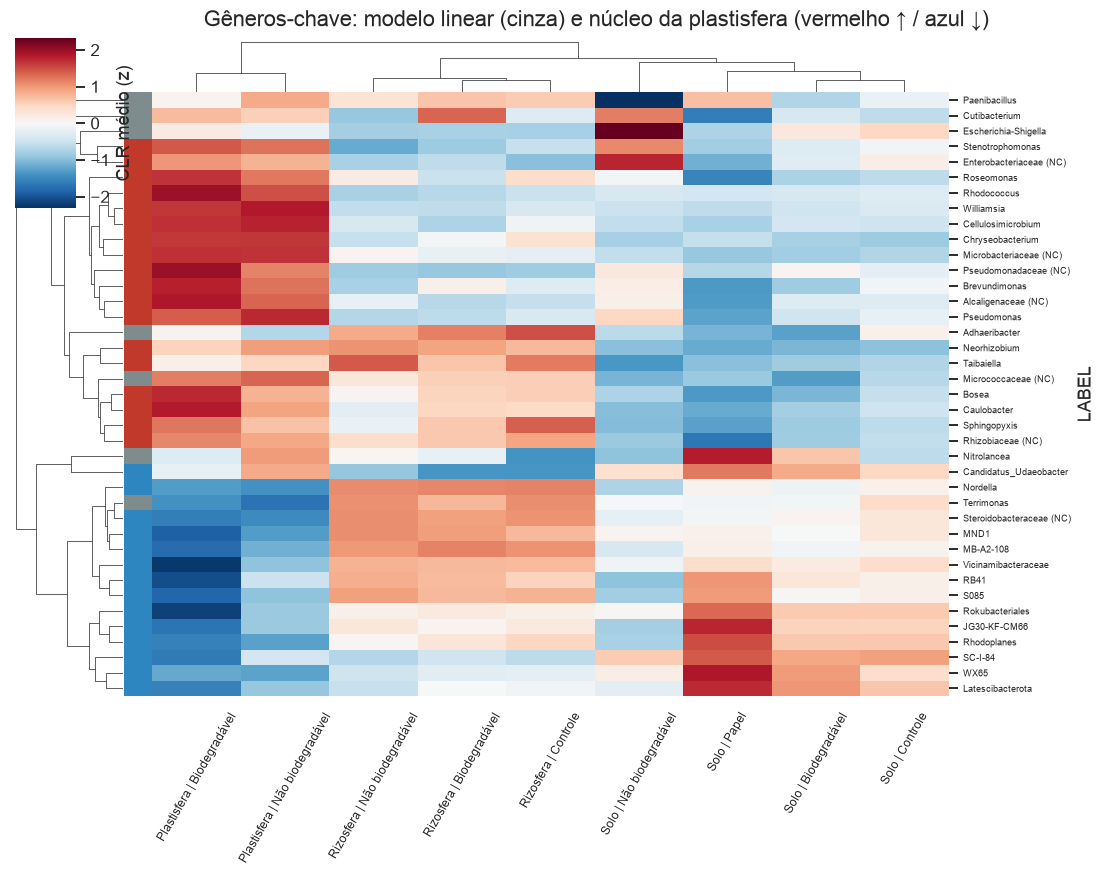

In [36]:
# (b) gêneros-chave (linear model q<0,05 + núcleo da plastisfera): CLR médio padronizado por compartimento × classe
chave = list(dict.fromkeys(list(LMG[LMG.q < .05].index) + list(plast.index[:30])))
chave = [g for g in chave if g in gcounts.index]
C_all = clr(gcounts.loc[gcounts.index.isin(chave) | ((gcounts > 0).mean(1) >= .2)]).loc[chave]
grp = meta.COMPARTIMENTO + ' | ' + meta.CLASSE
Hm = C_all.T.groupby(grp).mean().T
Hm = Hm[[c for c in Hm.columns if (grp == c).sum() >= 5]]
Hz = Hm.sub(Hm.mean(1), axis=0).div(Hm.std(1), axis=0)
row_col = pd.Series(['#c0392b' if g in plast.index and plast.at[g, 'direcao'].startswith('enr') else
                     '#2e86c1' if g in plast.index else '#7f8c8d' for g in Hz.index], index=Hz.index)
cg = sns.clustermap(Hz, cmap='RdBu_r', center=0, figsize=(11, max(8, .22 * len(Hz))), row_colors=row_col,
                    xticklabels=True, yticklabels=True, cbar_kws={'label': 'CLR médio (z)'}, dendrogram_ratio=(.12, .08))
cg.ax_heatmap.tick_params(axis='y', labelsize=6); cg.ax_heatmap.tick_params(axis='x', labelsize=8, rotation=60)
cg.fig.suptitle('Gêneros-chave: modelo linear (cinza) e núcleo da plastisfera (vermelho ↑ / azul ↓)', y=1.01)
plt.savefig(FIG / '09_heatmap_generos_chave.png', dpi=150); plt.show()

### 9.4 Indicator Species Analysis (ISA, IndVal.g)
IndVal de Dufrêne & Legendre (versão **IndVal.g**, corrigida para tamanhos de grupo desiguais):
`IndVal = √(A × B)`, onde **A** = especificidade (quanto da abundância média do gênero está naquele grupo) e
**B** = fidelidade (fração das amostras do grupo em que o gênero ocorre). Significância por 999 permutações dos rótulos
**restritas dentro de cada estudo/desenho**, e FDR (BH). Nível de gênero, abundância relativa.

In [37]:
def indval(samples, grupo, strata=None, perms=999, prev=0.05, seed=0):
    mm = meta.loc[samples]; X = gcounts[samples]; X = (X / X.sum()); X = X.loc[(X > 0).mean(1) >= prev]
    M = X.T.values; g = mm[grupo].astype(str).values; G = np.unique(g)
    def stat(lbl):
        mean = np.stack([M[lbl == k].mean(0) for k in G]); A_ = mean / np.clip(mean.sum(0, keepdims=True), 1e-300, None)
        B_ = np.stack([(M[lbl == k] > 0).mean(0) for k in G]); return np.sqrt(A_ * B_), A_, B_
    IV, A_, B_ = stat(g); best = IV.argmax(0); obs = IV.max(0)
    rng = np.random.default_rng(seed); cnt = np.ones(M.shape[1])
    blocks = [np.arange(len(g))] if strata is None else [np.where(mm[strata].values == s)[0] for s in mm[strata].unique()]
    for _ in range(perms):
        gp = g.copy()
        for b in blocks: gp[b] = rng.permutation(g[b])
        cnt += stat(gp)[0].max(0) >= obs - 1e-12
    r = pd.DataFrame({'grupo': G[best], 'IndVal': obs, 'A_especificidade': A_[best, range(len(best))],
                      'B_fidelidade': B_[best, range(len(best))], 'p': cnt / (perms + 1)}, index=X.index)
    r['q'] = multipletests(r.p, method='fdr_bh')[1]
    return r.join(tax_g[['Phylum', 'Family']]).sort_values(['grupo', 'IndVal'], ascending=[True, False])

def mostra_isa(r, n=12, nome=''):
    s = r[(r.q < .05) & (r.IndVal >= .5)]
    print(f'{nome}: {len(s)} indicadores (q<0,05 e IndVal≥0,5) —', s.grupo.value_counts().to_dict())
    display(s.groupby('grupo').head(n).round(3))

# (i) compartimento: desenhos com plastisfera e solo com o mesmo plástico
meta['DESENHO'] = np.select([meta.COLETA.eq('2016-09') & meta.SITIO.eq('Knoxville-TN'), meta.COLETA.eq('2016-09') & meta.SITIO.eq('MountVernon-WA'),
                             meta.BIOPROJECT.eq('PRJNA702448'), meta.BIOPROJECT.eq('PRJNA630025')], ['EUA-TN', 'EUA-WA', 'PBSA-DE', 'Alpes/Artico'], '')
s_i = list(meta.index[meta.DESENHO.ne('') & meta.CLASSE.isin(['Biodegradável', 'Não biodegradável'])])
ISA_comp = indval(s_i, 'COMPARTIMENTO', strata='DESENHO'); ISA_comp.round(4).to_csv(TAB / '09_isa_compartimento.csv')
mostra_isa(ISA_comp, nome='Compartimento (plastisfera × solo)')

Compartimento (plastisfera × solo): 354 indicadores (q<0,05 e IndVal≥0,5) — {'Solo': 255, 'Plastisfera': 99}


,grupo,IndVal,A_especificidade,B_fidelidade,p,q,Phylum,Family
LABEL,,,,,,,,
Pseudomonas,Plastisfera,0.914,0.835,1.000,0.001,0.002,Proteobacteria,Pseudomonadaceae
Sphingomonadaceae (NC),Plastisfera,0.909,0.877,0.942,0.001,0.002,Proteobacteria,Sphingomonadaceae
Massilia,Plastisfera,0.899,0.930,0.870,0.001,0.002,Proteobacteria,Oxalobacteraceae
Microbacteriaceae (NC),Plastisfera,0.899,0.962,0.841,0.001,0.002,Actinobacteriota,Microbacteriaceae
Rhodococcus,Plastisfera,0.889,0.974,0.812,0.001,0.002,Actinobacteriota,Nocardiaceae
Oxalobacteraceae (NC),Plastisfera,0.862,0.870,0.855,0.001,0.002,Proteobacteria,Oxalobacteraceae
Micrococcaceae (NC),Plastisfera,0.860,0.810,0.913,0.001,0.002,Actinobacteriota,Micrococcaceae
TM7a,Plastisfera,0.839,0.823,0.855,0.001,0.002,Patescibacteria,Saccharimonadaceae
Brevundimonas,Plastisfera,0.837,0.930,0.754,0.001,0.002,Proteobacteria,Caulobacteraceae


In [38]:
# (ii) classe do plástico no solo/rizosfera (estratos com controle), permutação dentro do estrato
ISA_classe = indval(s_ctrl, 'CLASSE', strata='ESTRATO'); ISA_classe.round(4).to_csv(TAB / '09_isa_classe.csv')
mostra_isa(ISA_classe, nome='Classe (controle / biodegradável / não biodegradável)')
# (iii) polímero na plastisfera de campo (PRJNA631499), permutação dentro do sítio
s_pl = list(meta.index[meta.BIOPROJECT.eq('PRJNA631499')])
ISA_pol = indval(s_pl, 'POLYMER', strata='SITIO'); ISA_pol.round(4).to_csv(TAB / '09_isa_polimero_plastisfera.csv')
mostra_isa(ISA_pol, nome='Polímero na plastisfera de campo')

Classe (controle / biodegradável / não biodegradável): 0 indicadores (q<0,05 e IndVal≥0,5) — {}


,grupo,IndVal,A_especificidade,B_fidelidade,p,q,Phylum,Family
LABEL,,,,,,,,


Polímero na plastisfera de campo: 105 indicadores (q<0,05 e IndVal≥0,5) — {'PE': 96, 'PLA/PHA': 4, 'starch/PBAT': 3, 'PLA/PBAT': 1, 'starch/Polyester blend': 1}


,grupo,IndVal,A_especificidade,B_fidelidade,p,q,Phylum,Family
LABEL,,,,,,,,
Sphaerisporangium,PE,0.927,0.860,1.000,0.001,0.013,Actinobacteriota,Streptosporangiaceae
Bryobacter,PE,0.927,0.859,1.000,0.001,0.013,Acidobacteriota,Bryobacteraceae
Blastocatellaceae (NC),PE,0.923,0.853,1.000,0.001,0.013,Acidobacteriota,Blastocatellaceae
Ellin6067,PE,0.891,0.795,1.000,0.001,0.013,Proteobacteria,Nitrosomonadaceae
bacteriap25,PE,0.888,0.901,0.875,0.001,0.013,Myxococcota,bacteriap25
Gemmatimonadaceae (NC),PE,0.886,0.785,1.000,0.001,0.013,Gemmatimonadota,Gemmatimonadaceae
Bacillus,PE,0.885,0.784,1.000,0.001,0.013,Firmicutes,Bacillaceae
Fictibacillus,PE,0.884,0.781,1.000,0.001,0.013,Firmicutes,Bacillaceae
Inquilinus,PE,0.877,0.878,0.875,0.001,0.013,Proteobacteria,Inquilinaceae


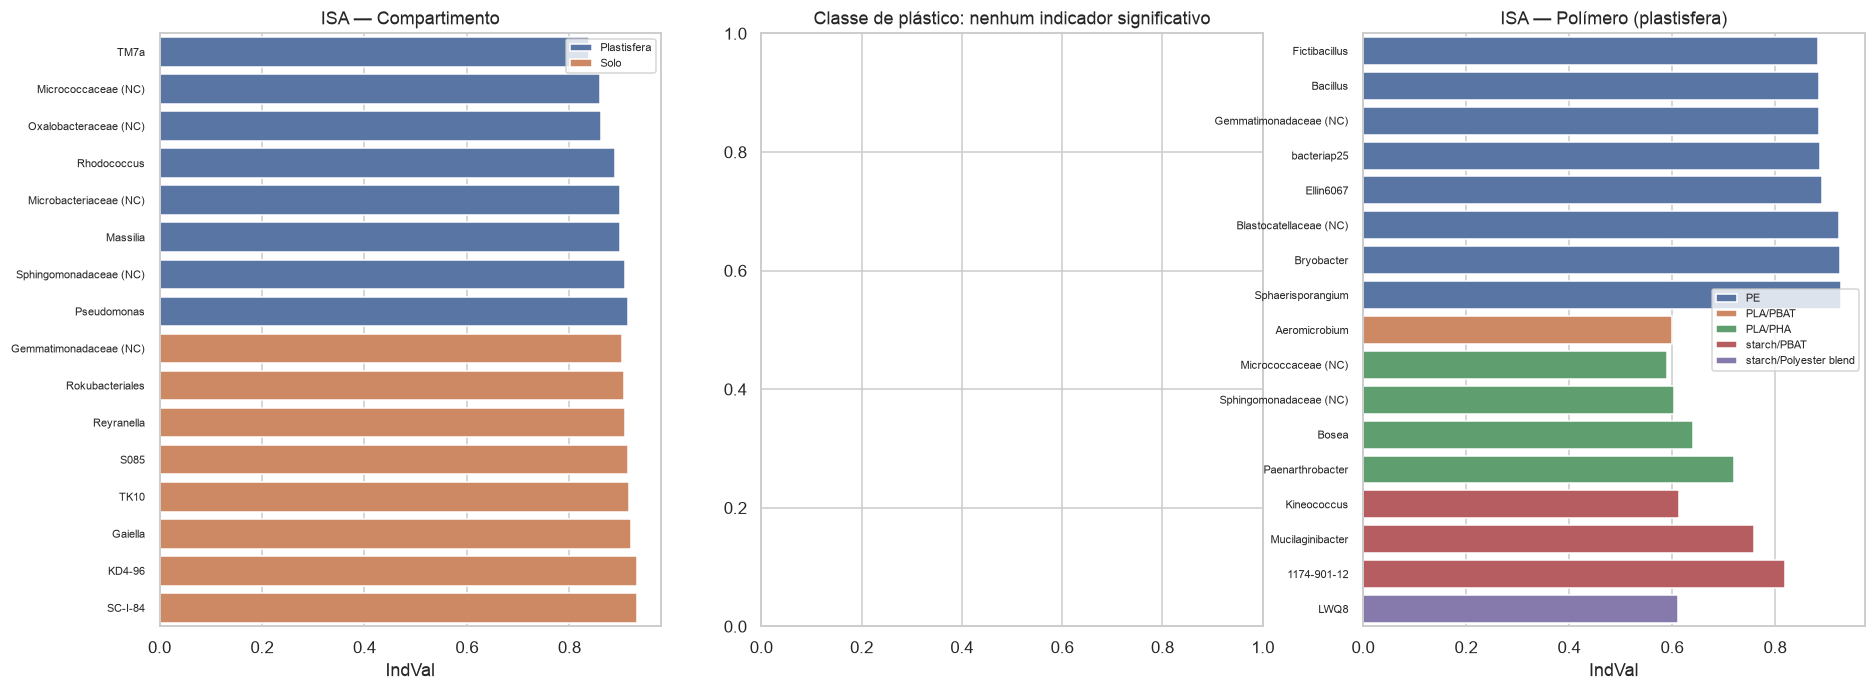

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, (r, t) in zip(axes, [(ISA_comp, 'Compartimento'), (ISA_classe, 'Classe de plástico'), (ISA_pol, 'Polímero (plastisfera)')]):
    top = r[(r.q < .05)].sort_values('IndVal', ascending=False).groupby('grupo').head(8).sort_values(['grupo', 'IndVal'])
    if top.empty: ax.set_title(f'{t}: nenhum indicador significativo'); continue
    sns.barplot(data=top.reset_index(), y='LABEL' if 'LABEL' in top.reset_index() else 'index', x='IndVal', hue='grupo', dodge=False, ax=ax)
    ax.set_title(f'ISA — {t}'); ax.set_ylabel(''); ax.tick_params(axis='y', labelsize=7); ax.legend(fontsize=7)
savefig('09_isa_indicadores')

### 9.5 db‑RDA (análise de redundância baseada em distância, Bray–Curtis)
Implementação equivalente a `vegan::capscale/dbrda`: PCoA da matriz de Bray–Curtis (eixos com autovalor positivo) →
regressão multivariada nas variáveis explicativas → PCA dos valores ajustados (eixos **CAP**). Testes por permutação
(999) do modelo e de cada termo (**marginal**, isto é, condicionado aos demais). Versão **parcial** remove primeiro o efeito do projeto.

In [40]:
def _dm(mm, terms):
    cols = []
    for t in terms:
        c = mm[t]
        if pd.api.types.is_numeric_dtype(c):
            c = c.fillna(c.mean()); cols.append(((c - c.mean()) / (c.std() or 1)).values[:, None])
        else:
            cols.append(pd.get_dummies(c.astype(object).fillna('NA').astype(str), drop_first=True).values.astype(float))
    return np.hstack(cols) if cols else np.zeros((len(mm), 0))

def dbrda(D, mm, constr, cond=(), perms=999, strata=None, seed=0):
    D = np.asarray(D); n = len(D); J = np.eye(n) - 1 / n; G = J @ (-0.5 * D ** 2) @ J
    w, V = np.linalg.eigh(G); pos = w > 1e-10 * w.max()
    Y = V[:, pos] * np.sqrt(w[pos]); inercia_neg = -w[w < 0].sum()
    tot = (Y ** 2).sum()
    Z = _dm(mm, cond); Z = Z - Z.mean(0) if Z.size else Z
    def resid(M, Zm):
        return M - Zm @ np.linalg.pinv(Zm) @ M if Zm.size else M
    Yr = resid(Y, Z); inercia_cond = tot - (Yr ** 2).sum()
    def ajuste(Ym, Xm):
        Xm = resid(Xm - Xm.mean(0), Z); H = Xm @ np.linalg.pinv(Xm); F_ = H @ Ym
        return F_, np.linalg.matrix_rank(Xm)
    X = _dm(mm, constr); Yfit, df = ajuste(Yr, X)
    ss_c = (Yfit ** 2).sum(); ss_r = ((Yr - Yfit) ** 2).sum(); dfr = n - 1 - (np.linalg.matrix_rank(Z) if Z.size else 0) - df
    Fobs = (ss_c / df) / (ss_r / dfr)
    rng = np.random.default_rng(seed)
    blocks = [np.arange(n)] if strata is None else [np.where(np.asarray(strata) == s)[0] for s in np.unique(strata)]
    def perm_p(Ym, Xm, d_, Fo):
        c = 1
        for _ in range(perms):
            p = np.arange(n)
            for b in blocks: p[b] = rng.permutation(b)
            Yp = Ym[p]; Fp_, _ = ajuste(Yp, Xm); sc = (Fp_ ** 2).sum(); sr = ((Yp - Fp_) ** 2).sum()
            c += (sc / d_) / (sr / dfr) >= Fo - 1e-12
        return c / (perms + 1)
    p_modelo = perm_p(Yr, X, df, Fobs)
    termos = []
    for t in constr:                                            # teste marginal de cada termo
        outros = [u for u in constr if u != t]
        Zt = np.hstack([Z, _dm(mm, outros)]) if (Z.size or outros) else Z
        Zt = Zt - Zt.mean(0) if Zt.size else Zt
        Yt = resid(Y, Zt); Xt = resid(_dm(mm, [t]) - _dm(mm, [t]).mean(0), Zt)
        Ht = Xt @ np.linalg.pinv(Xt); Ft = Ht @ Yt; dft = np.linalg.matrix_rank(Xt)
        if dft == 0:
            termos.append(dict(termo=t, gl=0, R2_marginal=0.0, F=np.nan, p=np.nan)); continue
        sct = (Ft ** 2).sum(); srt = ((Yt - Ft) ** 2).sum()
        Fo = (sct / dft) / (srt / dfr); c = 1
        for _ in range(perms):
            p = np.arange(n)
            for b in blocks: p[b] = rng.permutation(b)
            Yp = Yt[p]; Fp_ = Ht @ Yp; c += ((Fp_ ** 2).sum() / dft) / (((Yp - Fp_) ** 2).sum() / dfr) >= Fo - 1e-12
        termos.append(dict(termo=t, gl=dft, R2_marginal=sct / tot, F=Fo, p=c / (perms + 1)))
    U, S, Vt = np.linalg.svd(Yfit, full_matrices=False)
    k = int(min(df, (S > 1e-10).sum())); eig = S[:k] ** 2
    lc = Yfit @ Vt[:k].T; wa = Yr @ Vt[:k].T
    Xs = resid(X - X.mean(0), Z)
    return dict(R2_restrito=ss_c / tot, R2_condicional=inercia_cond / tot, F=Fobs, gl=df, p=p_modelo,
                prop_eixos=eig / tot, lc=lc, wa=wa, X=Xs, termos=pd.DataFrame(termos).set_index('termo'),
                inercia_neg_rel=inercia_neg / (tot + inercia_neg))

def resumo_dbrda(r, nome):
    print(f"{nome}: restrito R² = {r['R2_restrito']:.3f} (F = {r['F']:.2f}, p = {r['p']:.3f})"
          + (f"; condicional (removido) = {r['R2_condicional']:.3f}" if r['R2_condicional'] > 1e-9 else '')
          + f"; CAP1 = {r['prop_eixos'][0]*100:.1f}%" + (f", CAP2 = {r['prop_eixos'][1]*100:.1f}%" if len(r['prop_eixos']) > 1 else '')
          + f"; inércia negativa = {r['inercia_neg_rel']*100:.1f}%")
    display(r['termos'].round(4))

def plot_dbrda(r, mm, hue, style=None, ax=None, title='', generos=None, abund=None, n_gen=8):
    k = r['wa'].shape[1]
    d = pd.DataFrame(r['wa'][:, :2] if k >= 2 else np.column_stack([r['wa'][:, 0], np.zeros(len(mm))]),
                     index=mm.index, columns=['CAP1', 'CAP2']).join(mm[[hue] + ([style] if style else [])])
    sns.scatterplot(data=d, x='CAP1', y='CAP2', hue=hue, style=style, s=28, alpha=.8, ax=ax, palette='tab10')
    cen = d.groupby(hue)[['CAP1', 'CAP2']].mean()
    ax.scatter(cen.CAP1, cen.CAP2, marker='X', s=160, c='k')
    for lv, rr in cen.iterrows(): ax.annotate(str(lv), (rr.CAP1, rr.CAP2), fontsize=7, weight='bold')
    if abund is not None:                                     # gêneros: correlação com CAP1/CAP2 (setas)
        Cb = clr(abund[mm.index]); Cb = Cb.loc[(abund[mm.index] > 0).mean(1) >= .25]
        cor = pd.DataFrame({ax_: Cb.T.corrwith(d[ax_]) for ax_ in ['CAP1', 'CAP2']})
        top = cor.pow(2).sum(1).sort_values(ascending=False).head(n_gen).index
        sc = np.abs(d[['CAP1', 'CAP2']]).max().min() * .9
        for g_ in top:
            ax.arrow(0, 0, cor.at[g_, 'CAP1'] * sc, cor.at[g_, 'CAP2'] * sc, color='dimgrey', alpha=.7, head_width=sc * .03)
            ax.annotate(g_, (cor.at[g_, 'CAP1'] * sc * 1.08, cor.at[g_, 'CAP2'] * sc * 1.08), fontsize=6, color='dimgrey')
    pe = r['prop_eixos'] * 100
    ax.set_xlabel(f'CAP1 ({pe[0]:.1f}%)'); ax.set_ylabel(f'CAP2 ({pe[1]:.1f}%)' if len(pe) > 1 else 'CAP2')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=6)

db-RDA parcial global | Condition(projeto): restrito R² = 0.017 (F = 4.03, p = 0.005); condicional (removido) = 0.599; CAP1 = 1.2%, CAP2 = 0.2%; inércia negativa = 3.4%


,gl,R2_marginal,F,p
termo,,,,
SOIL_FRACTION,2,0.0102,6.2019,0.005
CLASSE,3,0.0055,2.2194,0.005


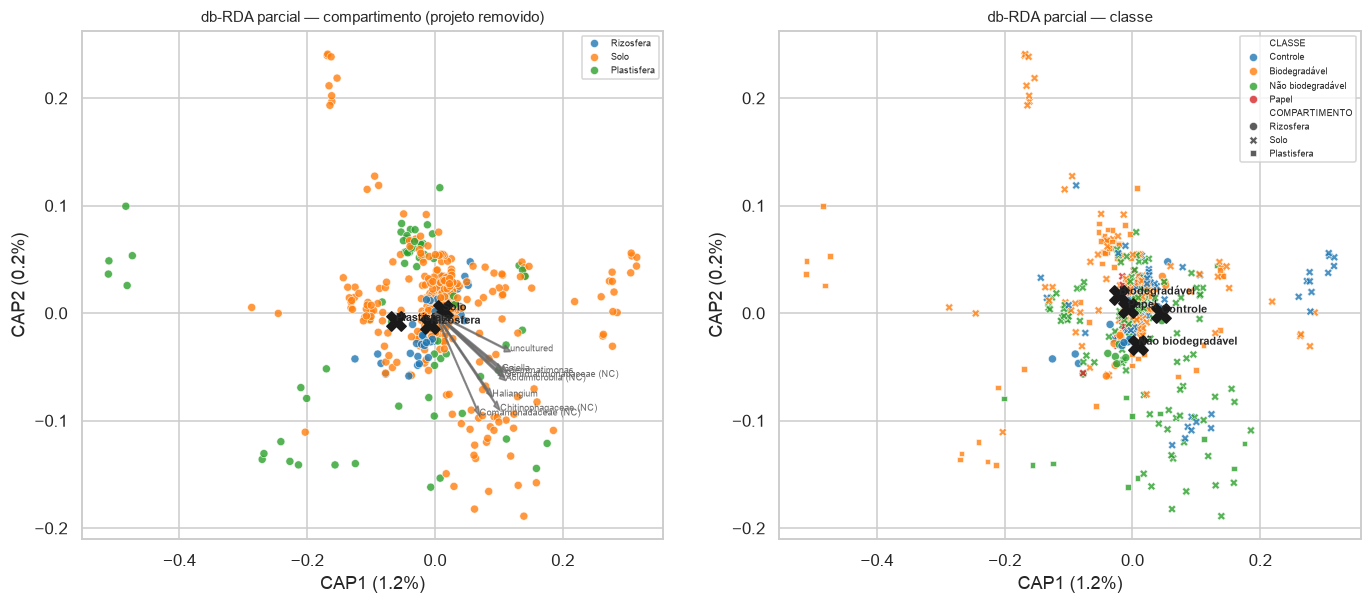

In [41]:
# (a) db-RDA PARCIAL global (gênero): efeito de fração + classe, removido o efeito do projeto
mt_ = meta.loc[gen_rel.columns]
r_glob = dbrda(bc_gen.data, mt_, ['SOIL_FRACTION', 'CLASSE'], cond=['BIOPROJECT'], perms=199, strata=mt_.BIOPROJECT.values)
resumo_dbrda(r_glob, 'db-RDA parcial global | Condition(projeto)')
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
plot_dbrda(r_glob, mt_, 'COMPARTIMENTO', None, ax[0], 'db-RDA parcial — compartimento (projeto removido)', abund=gcounts)
plot_dbrda(r_glob, mt_, 'CLASSE', 'COMPARTIMENTO', ax[1], 'db-RDA parcial — classe')
savefig('09_dbrda_global_parcial')

Projetos com dados completos: {'PRJNA564156': 84, 'PRJNA630025': 36, 'PRJNA1054347': 36, 'PRJNA631499': 20, 'PRJNA1021161': 1}
VIF: {'pH': 186.5, 'SOC_g_kg': 39.4, 'C_N': 68.0, 'ANNUAL_RAINFALL_mm': 389.6, 'AVG_ANNUAL_TEMPERATURE': 107.5}


db-RDA ambiental (permutação livre — n efetivo = nº de locais!): restrito R² = 0.452 (F = 28.17, p = 0.005); CAP1 = 20.7%, CAP2 = 14.2%; inércia negativa = 2.2%


,gl,R2_marginal,F,p
termo,,,,
pH,1,0.0378,11.7816,0.005
SOC_g_kg,1,0.0367,11.4391,0.005
C_N,1,0.0104,3.2426,0.035
ANNUAL_RAINFALL_mm,1,0.0333,10.3863,0.005
AVG_ANNUAL_TEMPERATURE,1,0.0357,11.1171,0.005


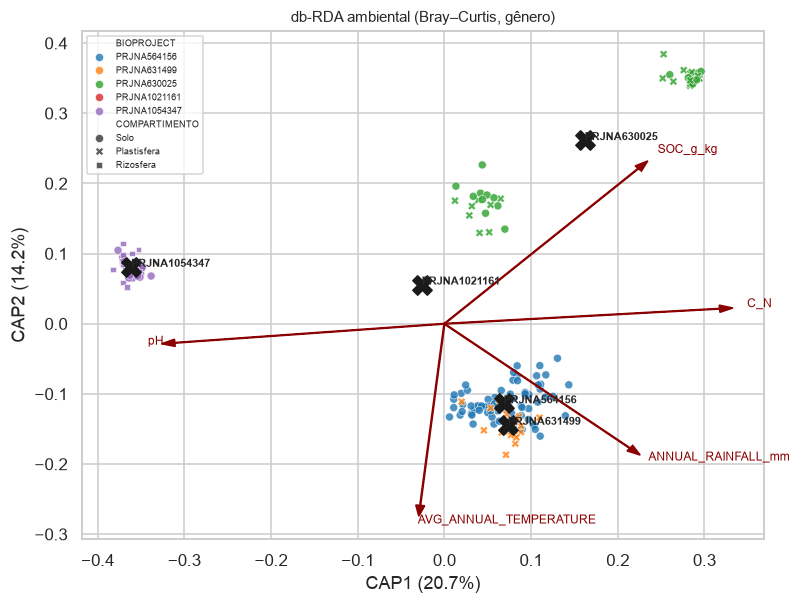

In [42]:
# (b) db-RDA ambiental: variáveis de solo/clima (amostras com dados completos). ATENÇÃO: confundido com o projeto.
env_v = ['pH', 'SOC(g/kg)', 'C/N', 'ANNUAL_RAINFALL(mm)', 'AVG_ANNUAL_TEMPERATURE']
ok = mt_[env_v].notna().all(1); s_env = list(mt_.index[ok])
idx = [list(gen_rel.columns).index(s) for s in s_env]
mm_env = mt_.loc[s_env].rename(columns=lambda c: c.replace('(', '_').replace(')', '').replace('/', '_'))
env_c = [c.replace('(', '_').replace(')', '').replace('/', '_') for c in env_v]
Xv = mm_env[env_c]; vif = pd.Series(np.diag(np.linalg.pinv(np.corrcoef(Xv.values, rowvar=False))), index=env_c)
print('Projetos com dados completos:', mm_env.BIOPROJECT.value_counts().to_dict()); print('VIF:', vif.round(1).to_dict())
r_env = dbrda(bc_gen.data[np.ix_(idx, idx)], mm_env, env_c, perms=199)
resumo_dbrda(r_env, 'db-RDA ambiental (permutação livre — n efetivo = nº de locais!)')
fig, ax = plt.subplots(figsize=(8, 6))
plot_dbrda(r_env, mm_env, 'BIOPROJECT', 'COMPARTIMENTO', ax, 'db-RDA ambiental (Bray–Curtis, gênero)')
lcs = np.abs(r_env['wa'][:, :2]).max(0).min() * .9
for j, v in enumerate(env_c):
    c1 = np.corrcoef(r_env['X'][:, j], r_env['lc'][:, 0])[0, 1]; c2 = np.corrcoef(r_env['X'][:, j], r_env['lc'][:, 1])[0, 1]
    ax.arrow(0, 0, c1 * lcs, c2 * lcs, color='darkred', head_width=lcs * .03); ax.annotate(v, (c1 * lcs * 1.1, c2 * lcs * 1.1), color='darkred', fontsize=8)
savefig('09_dbrda_ambiental')

PRJNA564156 | constr=['POLYMER'] | cond=['SITIO', 'COLETA']: restrito R² = 0.033 (F = 1.92, p = 0.002); condicional (removido) = 0.513; CAP1 = 1.4%, CAP2 = 0.7%; inércia negativa = -0.0%


,gl,R2_marginal,F,p
termo,,,,
POLYMER,6,0.0333,1.918,0.002


PRJNA1054347 | constr=['SOIL_FRACTION', 'POLYMER'] | cond=[]: restrito R² = 0.269 (F = 3.93, p = 0.002); CAP1 = 14.7%, CAP2 = 8.1%; inércia negativa = -0.0%


,gl,R2_marginal,F,p
termo,,,,
SOIL_FRACTION,1,0.1098,4.8063,0.002
POLYMER,2,0.1594,3.4896,0.002


PRJNA631499 | constr=['POLYMER'] | cond=['SITIO']: restrito R² = 0.157 (F = 2.72, p = 0.002); condicional (removido) = 0.351; CAP1 = 8.5%, CAP2 = 4.3%; inércia negativa = 0.0%


,gl,R2_marginal,F,p
termo,,,,
POLYMER,4,0.1573,2.7216,0.002


... (2 outputs left out)

PRJNA1155845 | constr=['GLIFOSATO', 'POLYMER'] | cond=[]: restrito R² = 0.844 (F = 36.13, p = 0.002); CAP1 = 79.0%, CAP2 = 3.8%; inércia negativa = 0.0%


,gl,R2_marginal,F,p
termo,,,,
GLIFOSATO,1,0.0188,2.4188,0.004
POLYMER,2,0.8254,52.9852,0.002


PRJNA1021161 | constr=['DIAS', 'POLYMER', 'ENVELHECIMENTO'] | cond=[]: restrito R² = 0.071 (F = 1.60, p = 0.006); CAP1 = 3.3%, CAP2 = 1.9%; inércia negativa = 0.5%


,gl,R2_marginal,F,p
termo,,,,
DIAS,1,0.0190,2.1486,0.014
POLYMER,1,0.0069,0.7778,0.620
ENVELHECIMENTO,2,0.0333,1.8848,0.114


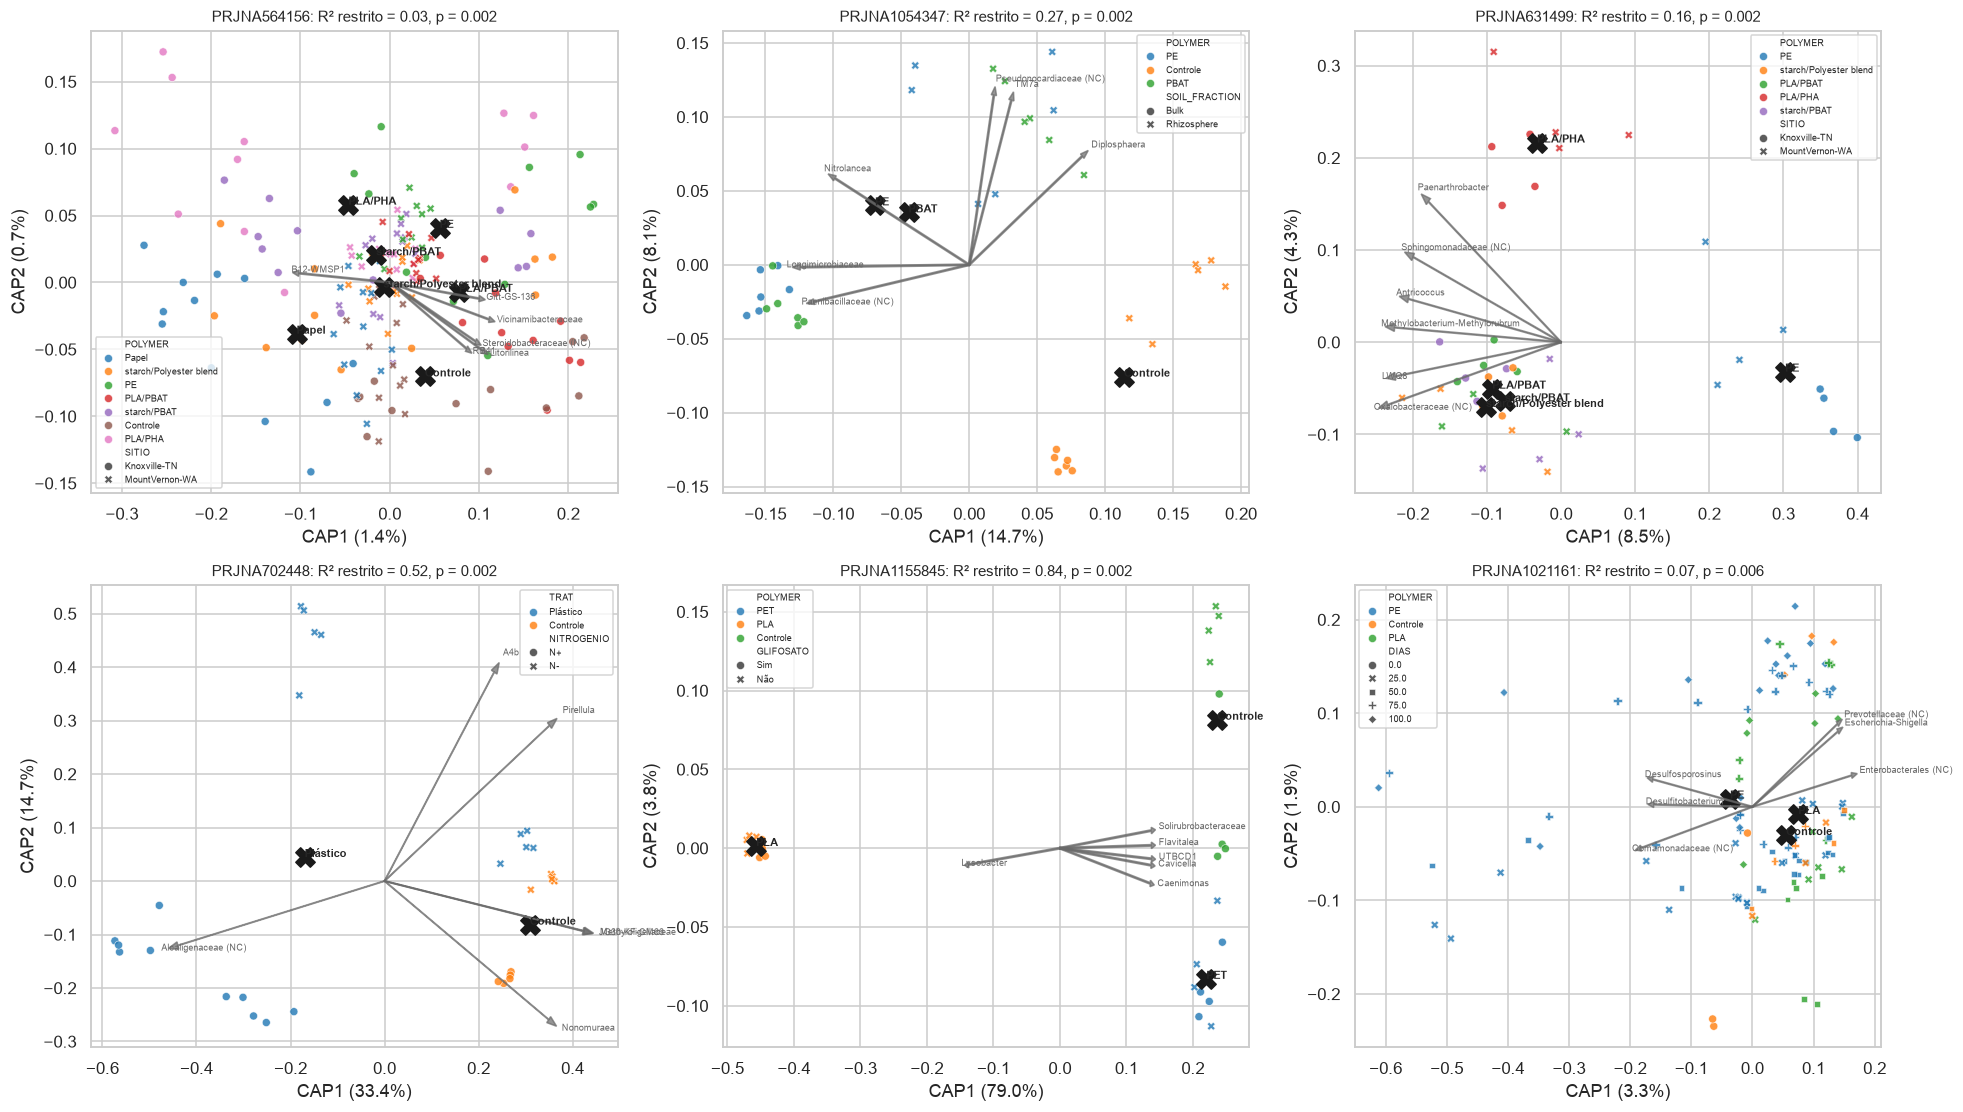

In [43]:
# (c) db-RDA dentro de projetos (ASV, rarefeito, Bray–Curtis)
casos = [('PRJNA564156', ['POLYMER'], ['SITIO', 'COLETA'], 'SITIO'),
         ('PRJNA1054347', ['SOIL_FRACTION', 'POLYMER'], [], None),
         ('PRJNA631499', ['POLYMER'], ['SITIO'], 'SITIO'),
         ('PRJNA702448', ['NITROGENIO', 'SOIL_FRACTION', 'TRAT'], [], None),
         ('PRJNA1155845', ['GLIFOSATO', 'POLYMER'], [], None),
         ('PRJNA1021161', ['DIAS', 'POLYMER', 'ENVELHECIMENTO'], [], None)]
DB = {}
fig, axes = plt.subplots(2, 3, figsize=(21, 12))
for ax, (pj, constr, cond, st) in zip(axes.flat, casos):
    s = list(meta.index[meta.BIOPROJECT == pj]); mm = meta.loc[s].copy()
    X = rare[s]; X = X.loc[X.sum(1) > 0]
    D = beta_diversity('braycurtis', X.T.values, ids=s).data
    r = dbrda(D, mm, constr, cond=cond, perms=499, strata=(mm[cond[0]].values if cond else None))
    DB[pj] = r; resumo_dbrda(r, f'{pj} | constr={constr} | cond={cond}')
    plot_dbrda(r, mm, 'POLYMER' if 'POLYMER' in constr else 'TRAT', st or (constr[0] if constr[0] != 'POLYMER' else None), ax,
               f"{pj}: R² restrito = {r['R2_restrito']:.2f}, p = {r['p']:.3f}", abund=gcounts, n_gen=6)
savefig('09_dbrda_por_projeto')
pd.concat({k: v['termos'] for k, v in DB.items()}).round(4).to_csv(TAB / '09_dbrda_por_projeto_termos.csv')

## 10. Resumo numérico para as conclusões

In [44]:
print('Amostras:', meta.shape[0], '| projetos:', meta.BIOPROJECT.nunique(), '| ASVs após filtro:', counts.shape[0], '| profundidade rarefação:', DEPTH)
print('\nTop 8 filos (% médio):'); print((phy.loc[top_phy].mean(1) * 100).round(1).head(8).to_string())
print('\nMeta-análise alfa:'); print(MA.round(3).to_string())
print('\nPERMANOVA global:'); print(glob.round(3).to_string()); print(glob2.round(3).to_string())
print('\nPERMANOVA por projeto (termos do plástico):')
print(PP[PP.termo.isin(['POLYMER','TRAT','GLIFOSATO','PxG','DOSE','ENVELHECIMENTO','DIAS'])].round(3).to_string())
for nome in DA:
    r = DA[nome]; print(f'\n{nome}: q<0.05 → {(r.q<.05).sum()} ( ↑ {((r.q<.05)&(r.log_fc>0)).sum()} / ↓ {((r.q<.05)&(r.log_fc<0)).sum()} )')
    print(r.query('q<0.05')[['k','log_fc','q','consist','Phylum']].round(3).head(15).to_string())

Amostras: 483 | projetos: 9 | ASVs após filtro: 47190 | profundidade rarefação: 12000

Top 8 filos (% médio):
Phylum
Proteobacteria      25.9
Acidobacteriota     13.5
Actinobacteriota    12.1
Chloroflexi          9.9
Firmicutes           8.4
Bacteroidota         6.9
Planctomycetota      6.3
Patescibacteria      3.8

Meta-análise alfa:
                                                     comparacao  metrica  k_estudos      g  IC95_inf  IC95_sup      p     I2
0                                  Plástico (todos) vs Controle  FaithPD          8 -0.179    -0.665     0.308  0.472  0.667
1                                  Plástico (todos) vs Controle   Pielou          8  0.264    -0.483     1.010  0.489  0.850
2                                  Plástico (todos) vs Controle  Riqueza          8 -0.155    -0.740     0.430  0.603  0.766
3                                  Plástico (todos) vs Controle  Shannon          8  0.058    -0.598     0.714  0.864  0.812
4                                     